# GNSS Spoofing Detection by AoA Comparison

This notebook follows the paper flow for **GNSS Spoofing Detection by Estimating Angle of Arrival based on Carrier Phase Double Difference Measurements**.

The experiment configuration is controlled by one scenario flag, one spoof-PRN input list, and an optional hard-coded reference PRN. The current partial-spoof experiment uses the PRN selected by `HARDCODED_REFERENCE_SVID` as the DD reference, estimates DD-method AoA, compares it with ephemeris-based AoA, and checks u-blox `NAV-SAT.svUsed` over every NAV-SAT epoch in both receivers.


## Paper Algorithm Summary

1. Read carrier-phase measurements and navigation messages from two receivers.
2. Synchronize receiver RAWX epochs by receiver time of week.
3. Build author-aligned carrier phase: `RXM-RAWX.cpMes + NAV-PVT.nano * 1e-9 * RXM-RAWX.doMes`.
4. Compute receiver single differences.
5. Select a reference satellite and compute satellite double differences.
6. Apply the paper rounding operation to obtain fractional double differences.
7. Convert DD values to DD-method AoA using the reference-angle anchor.
8. Compare DD-method AoA with ephemeris-based AoA from NAV-SAT azimuth/elevation.
9. For partial spoofing, test whether the spoof PRNs converge to a common DD-method AoA while remaining distinct in ephemeris-based AoA.
10. Check `svUsed` over the full NAV-SAT timeline, not only the selected AoA window.


## Paper-to-Code Mapping

| Implementation artifact | Paper meaning |
| --- | --- |
| `carrier_phase_cycles` | Author-aligned carrier phase observable from Eq. 8 |
| `single_difference_cycles` | Receiver single difference from Eq. 9 |
| `double_difference_cycles` | Satellite double difference from Eq. 14 |
| `rounded_dd_cycles` | Integer round operation used in Eq. 17 and Eq. 18 |
| `fractional_dd_cycles` | Fractional DD after subtracting rounded DD, Eq. 18 |
| `candidate_aoa_deg` | Eq. 21 branch candidates for `m in {-2, -1, 0, 1, 2}` |
| `selected_aoa_deg` | Dynamic-programming selected DD-method AoA path from Algorithm 1 |
| `ephemeris_aoa_*_deg` | Baseline-relative AoA derived from receiver NAV-SAT azimuth/elevation |
| `sv_used_*` | Receiver NAV-SAT `svUsed` timeline over all NAV-SAT epochs |


In [245]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    aggregate_pairwise_geometry_residuals,
    classify_pairwise_geometry,
    compute_pairwise_geometry_residuals,
    DatasetConfig,
    plot_aoa_method_comparison,
    plot_aoa_tracks,
    plot_candidate_cloud,
    plot_double_difference,
    plot_fractional_dd,
    plot_sv_used_timeline,
    plot_valid_m_candidates,
    run_paper_scenario,
)

pd.set_option("display.max_columns", 80)


## Scenario Configuration

Set `PARTIAL_SPOOF_ENABLED`, `SPOOF_SVIDS`, and `HARDCODED_REFERENCE_SVID` for the experiment. The current dataset is a partial-spoof scenario where PRNs 6, 9, 11, and 20 are the spoof input list.

When `reference_svid` is set, it is an authoritative manual override: the pipeline uses that PRN even when it is listed as spoofed or excluded from automatic reference selection. The PRN must still be present with common valid carrier-phase epochs in both receivers. This scenario uses the PRN selected by `HARDCODED_REFERENCE_SVID` and derives its scalar reference-angle anchor from the median of available Receiver 1 NAV-SAT samples in the selected valid AoA window. Set `HARDCODED_REFERENCE_SVID = None` to restore automatic non-spoof reference selection.


In [246]:
RUN_FULL = False
DEFAULT_LENGTH = None if RUN_FULL else 500
OUTPUT_ROOT = Path("outputs/aoa_paper")

PARTIAL_SPOOF_ENABLED = True
SPOOF_SVIDS = (20,11,6,9)
HARDCODED_REFERENCE_SVID = 12  # Current fixed DD reference.
EXCLUDED_ANALYSIS_SVIDS = ()
CONVERGENCE_THRESHOLD_DEG = 5.0
SCORE_THRESHOLD = 0.5

# Single-difference receiver order = baseline polarity. "rx1-rx2" (default) or "rx2-rx1".
# The two give supplementary AoA (alpha vs 180-alpha); pick the one that makes DD-method AoA
# agree with the ephemeris-based AoA for this rig (i.e. matching which antenna is the north
# end of the baseline). Equivalent alternative: keep "rx1-rx2" and set navsat_azimuth_bias_deg=180.
SINGLE_DIFFERENCE_ORDER = "rx2-rx1"

SCENARIO_CONFIG = DatasetConfig(
    name=f"sp-partial-19-06/18-06-prn{HARDCODED_REFERENCE_SVID}-pairwise",
    receiver1_path=Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
    receiver2_path=Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
    alpha_r_deg=None,
    reference_svid=HARDCODED_REFERENCE_SVID,
    selected_svids=SPOOF_SVIDS if PARTIAL_SPOOF_ENABLED else None,
    excluded_reference_svids=tuple(dict.fromkeys((*SPOOF_SVIDS, *EXCLUDED_ANALYSIS_SVIDS))) if PARTIAL_SPOOF_ENABLED else EXCLUDED_ANALYSIS_SVIDS,
    reference_required_svids=SPOOF_SVIDS if PARTIAL_SPOOF_ENABLED else None,
    excluded_analysis_svids=EXCLUDED_ANALYSIS_SVIDS,
    start_index=0,
    length=DEFAULT_LENGTH,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order=SINGLE_DIFFERENCE_ORDER,
    navsat_azimuth_bias_deg=0.0,
    output_root=OUTPUT_ROOT,
)

pd.DataFrame(
    [
        {
            "name": SCENARIO_CONFIG.name,
            "receiver1_path": str(SCENARIO_CONFIG.receiver1_path),
            "receiver2_path": str(SCENARIO_CONFIG.receiver2_path),
            "partial_spoof_enabled": PARTIAL_SPOOF_ENABLED,
            "spoof_svids": SPOOF_SVIDS,
            "hardcoded_reference_svid": SCENARIO_CONFIG.reference_svid,
            "excluded_analysis_svids": EXCLUDED_ANALYSIS_SVIDS,
            "single_difference_order": SCENARIO_CONFIG.single_difference_order,
            "navsat_azimuth_bias_deg": SCENARIO_CONFIG.navsat_azimuth_bias_deg,
            "length": SCENARIO_CONFIG.length,
            "output_dir": str(SCENARIO_CONFIG.output_dir),
        }
    ]
)


,name,receiver1_path,receiver2_path,partial_spoof_enabled,spoof_svids,hardcoded_reference_svid,excluded_analysis_svids,single_difference_order,navsat_azimuth_bias_deg,length,output_dir
0,sp-partial-19-06/18-06-prn12-pairwise,dataset/sp-partial-19-06/18-06/COM3___9600_260...,dataset/sp-partial-19-06/18-06/COM4___9600_260...,True,"(20, 11, 6, 9)",12,(),rx2-rx1,0.0,500,outputs/aoa_paper/sp-partial-19-06/18-06-prn12...


## Run Paper Scenario

The notebook delegates experiment logic to `aoa_pipeline.run_paper_scenario`. That function handles UBX parsing, synchronization, reference selection, DD-method AoA generation, ephemeris-based AoA generation, all-epoch `svUsed`, CSV saving, and plot artifact saving.


In [247]:
scenario = run_paper_scenario(
    SCENARIO_CONFIG,
    partial_spoof_enabled=PARTIAL_SPOOF_ENABLED,
    spoof_svids=SPOOF_SVIDS,
    convergence_threshold_deg=CONVERGENCE_THRESHOLD_DEG,
    save_outputs=True,
)

result = scenario.analysis_result
all_satellite_result = scenario.all_satellite_result
scenario.run_summary


,dataset,partial_spoof_enabled,spoof_svids,excluded_analysis_svids,reference_svid,reference_alpha_deg,navsat_azimuth_bias_deg,source_epoch_start,analysis_epoch_count,all_satellite_dd_tracks,output_dir,rx_Receiver 1_sv20_used_epoch_count,rx_Receiver 1_sv11_used_epoch_count,rx_Receiver 1_sv6_used_epoch_count,rx_Receiver 1_sv9_used_epoch_count,rx_Receiver 2_sv20_used_epoch_count,rx_Receiver 2_sv11_used_epoch_count,rx_Receiver 2_sv6_used_epoch_count,rx_Receiver 2_sv9_used_epoch_count
0,sp-partial-19-06/18-06-prn12-pairwise,True,"(20, 11, 6, 9)",(),12,107.694647,0.0,0,34,12,outputs/aoa_paper/sp-partial-19-06/18-06-prn12...,0,0,1,0,0,0,3,0


## Receiver Synchronization and Reference Satellite

This corresponds to the paper setup before computing carrier-phase double differences. In this scenario, the manual override selects authentic PRN 23 as the reference; automatic ranking is bypassed.


In [248]:
display(result.epochs.head())

if scenario.probe_result is not None:
    print("Reference ranking from the partial-spoof probe run")
    display(scenario.probe_result.reference_selection.head(10))
else:
    display(result.reference_selection.head(10))

if not scenario.reference_alpha_by_epoch.empty:
    print("Reference-angle anchor matched from Receiver 1 NAV-SAT")
    display(scenario.reference_alpha_by_epoch.head())


,epoch_index,source_epoch_index,week,sync_tow,rcvTow_rx1,rcvTow_rx2,tow_delta_s
0,0,0,2423,381076.0,381075.997,381075.997,0.0
1,1,1,2423,381077.0,381076.997,381076.997,0.0
2,2,2,2423,381078.0,381077.997,381077.997,0.0
3,3,3,2423,381079.0,381078.997,381078.997,0.0
4,4,4,2423,381080.0,381079.997,381079.997,0.0


Reference ranking from the partial-spoof probe run


,svid,valid_epoch_count,longest_continuous_run,mean_cno,median_abs_phase_step_cycles,manual_override
0,12,34,34,34.073529,NaN,True


Reference-angle anchor matched from Receiver 1 NAV-SAT


,epoch_index,rcvTow_rx1,navsat_rcvTow,reference_svid,reference_elev_deg,reference_azim_deg,reference_cno,reference_svUsed,reference_alpha_deg
0,0,381075.997,381076.0,12.0,21.0,109.0,33.0,1.0,107.694647
1,1,381076.997,381077.0,12.0,21.0,109.0,33.0,1.0,107.694647
2,2,381077.997,381078.0,12.0,21.0,109.0,34.0,1.0,107.694647
3,3,381078.997,381079.0,12.0,21.0,109.0,33.0,1.0,107.694647
4,4,381079.997,381080.0,12.0,21.0,109.0,33.0,1.0,107.694647


## Carrier Phase, Single Difference, and Double Difference

These tables expose the main measurement path before AoA conversion.


In [249]:
print(result.config.name)
print(f"Reference SV: {result.reference_svid}")

display(result.carrier_phase_cycles.head())
display(result.single_difference_cycles.head())
display(result.double_difference_cycles.head())


sp-partial-19-06/18-06-prn12-pairwise
Reference SV: 12


rx1                                            \
                       12            20            11            6    
epoch_index                                                           
0            1.195901e+08  1.025499e+08  1.098135e+08  1.205509e+08   
1            1.195905e+08  1.025541e+08  1.098167e+08  1.205551e+08   
2            1.195910e+08  1.025582e+08  1.098200e+08  1.205593e+08   
3            1.195916e+08  1.025624e+08  1.098232e+08  1.205636e+08   
4            1.195921e+08  1.025665e+08  1.098264e+08  1.205678e+08   

                                    rx2                              \
                       9             12            20            11   
epoch_index                                                           
0            1.179524e+08  1.204565e+08  1.034164e+08  1.106800e+08   
1            1.179551e+08  1.204557e+08  1.034192e+08  1.106819e+08   
2            1.179577e+08  1.204548e+08  1.034220e+08  1.106837e+08   
3            1.179604e+08  1.204539e+08  1.034247e+08  1.106856e+08   
4            1.179631e+08  1.204530e+08  1.034275e+08  1.106874e+08   

                                         
                       6             9   
epoch_index                              
0            1.214174e+08  1.188189e+08  
1            1.214202e+08  1.188202e+08  
2            1.214231e+08  1.188215e+08  
3            1.214259e+08  1.188228e+08  
4            1.214288e+08  1.188241e+08

,6,9,11,12,20
epoch_index,,,,,
0,866512.200748,866541.182078,866514.186532,866497.619769,866513.183587
1,865130.970375,865159.984415,865132.985244,865116.421694,865131.992396
2,863748.504434,863777.485444,863750.486340,863733.884427,863749.490650
3,862364.850598,862393.857876,862366.856263,862350.279317,862365.855146
4,860980.085548,861009.090559,860982.078553,860965.514399,860981.087477


,20,11,6,9
epoch_index,,,,
0,15.563819,16.566763,14.580979,43.562309
1,15.570702,16.563550,14.548681,43.562721
2,15.606224,16.601913,14.620007,43.601017
3,15.575829,16.576946,14.571281,43.578558
4,15.573079,16.564155,14.571149,43.576161


## Rounding and Fractional DD

This is the paper rounding step. The mixed-case analysis uses authentic PRN 23 as the fixed reference. The fractional-DD figure below plots every valid PRN from the all-satellite result and highlights spoof PRNs 6, 9, 11, and 20.


In [250]:
display(result.rounded_dd_cycles.head())
display(result.fractional_dd_cycles.head())
display(result.collapse_metrics)


,20,11,6,9
epoch_index,,,,
0,16.0,17.0,15.0,44.0
1,16.0,17.0,15.0,44.0
2,16.0,17.0,15.0,44.0
3,16.0,17.0,15.0,44.0
4,16.0,17.0,15.0,44.0


,20,11,6,9
epoch_index,,,,
0,-0.436181,-0.433237,-0.419021,-0.437691
1,-0.429298,-0.436450,-0.451319,-0.437279
2,-0.393776,-0.398087,-0.379993,-0.398983
3,-0.424171,-0.423054,-0.428719,-0.421442
4,-0.426921,-0.435845,-0.428851,-0.423839


,usable_epoch_count,total_epoch_count,median_dispersion_cycles,p90_dispersion_cycles,median_mad_cycles,pct_epochs_dispersion_le_0p05_cycles,pct_epochs_dispersion_le_0p1_cycles,pct_epochs_dispersion_le_0p15_cycles
0,34,34,0.014933,0.025731,0.002418,100.0,100.0,100.0


## AoA by Measurement Method and Ephemeris Method

The DD-method AoA comes from carrier-phase double differences. The ephemeris-based AoA comes from receiver NAV-SAT azimuth/elevation. For the partial-spoof case, spoof PRNs 6, 9, 11, and 20 should converge in DD-method AoA but remain distinct in ephemeris-based AoA.


In [251]:
print("All-satellite DD-method AoA")
display(scenario.all_satellite_dd_method_aoa_deg.head())

print("All-satellite ephemeris-based AoA from Receiver 1 NAV-SAT")
display(scenario.ephemeris_aoa_rx1_deg.head())

print("All-satellite ephemeris-based AoA from Receiver 2 NAV-SAT")
display(scenario.ephemeris_aoa_rx2_deg.head())


All-satellite DD-method AoA


,6,9,10,11,12,13,15,18,20,23,24,32
epoch_index,,,,,,,,,,,,
0,73.916667,75.026910,90.183135,74.762578,107.694647,103.994098,117.947783,114.410656,74.937375,112.774841,102.218114,119.570282
1,75.833709,75.002474,90.201519,74.953326,107.694647,104.442257,118.119183,112.658574,74.528583,112.324915,99.903244,119.768832
2,71.574995,72.718106,88.118013,72.664338,107.694647,106.930311,116.110250,113.246780,72.405415,110.670841,100.051510,116.879378
3,74.494168,74.060980,88.701609,74.157023,107.694647,105.901397,116.018889,113.069863,74.223543,112.042900,98.958006,118.384316
4,74.501960,74.203781,89.441102,74.917428,107.694647,103.506032,117.989381,112.104301,74.387216,110.242420,97.998665,118.803211


All-satellite ephemeris-based AoA from Receiver 1 NAV-SAT


,6,9,10,11,12,13,15,18,20,23,24,32
epoch_index,,,,,,,,,,,,
0,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,76.333661
1,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,76.333661
2,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,75.486302
3,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,75.486302
4,75.088329,80.670347,43.500553,53.89629,107.694647,NaN,64.512318,128.746285,75.275561,63.544458,48.771994,75.486302


All-satellite ephemeris-based AoA from Receiver 2 NAV-SAT


,6,9,10,11,12,13,15,18,20,23,24,32
epoch_index,,,,,,,,,,,,
0,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,76.333661
1,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,76.333661
2,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,75.486302
3,NaN,NaN,43.500553,NaN,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,75.486302
4,75.088329,80.670347,43.500553,53.89629,107.694647,NaN,64.512318,128.746285,NaN,63.544458,48.771994,75.486302


## Partial-Spoof Convergence

This section is conditional on `PARTIAL_SPOOF_ENABLED`. The spoof-only DD-method AoA plot does not include a cluster median line.


In [252]:
if PARTIAL_SPOOF_ENABLED:
    print("Joint-source DD-method AoA for spoof PRNs")
    display(scenario.joint_source_aoa_deg.head())

    print("Pairwise convergence among spoof PRNs")
    display(scenario.pairwise_convergence)

    print("Converged clusters")
    display(scenario.cluster_summary)
else:
    print("Partial-spoof convergence is disabled for this scenario.")


Joint-source DD-method AoA for spoof PRNs


,20,11,6,9
epoch_index,,,,
0,74.937375,74.762578,73.916667,75.026910
1,74.528583,74.953326,75.833709,75.002474
2,72.405415,72.664338,71.574995,72.718106
3,74.223543,74.157023,74.494168,74.060980
4,74.387216,74.917428,74.501960,74.203781


Pairwise convergence among spoof PRNs


,pair,left_svid,right_svid,epoch_count,median_abs_aoa_diff_deg,mean_abs_aoa_diff_deg,p90_abs_aoa_diff_deg,max_abs_aoa_diff_deg,pct_epochs_aoa_diff_le_threshold,threshold_deg
0,20-11,20,11,34,0.180695,0.283132,0.684620,0.927485,100.0,5.0
1,20-6,20,6,34,0.684583,0.778664,1.393762,2.768057,100.0,5.0
2,20-9,20,9,34,0.233255,0.289490,0.592904,0.873725,100.0,5.0
3,11-6,11,6,34,0.656434,0.802740,1.537053,2.704056,100.0,5.0
4,11-9,11,9,34,0.250347,0.300003,0.662987,0.959467,100.0,5.0
5,6-9,6,9,34,0.676407,0.805600,1.360528,2.592124,100.0,5.0


Converged clusters


,cluster_svids,cluster_size,epoch_count,median_aoa_deg,mean_aoa_deg,std_epoch_median_aoa_deg,median_spread_deg,p90_spread_deg,threshold_deg
0,"6,9,11,20",4,34,72.898601,72.94627,1.180748,0.897561,1.559186,5.0


## Receiver svUsed Over All NAV-SAT Epochs

This is intentionally computed over each receiver's full native NAV-SAT timeline, not the shortened DD-method AoA window. This catches cases where a spoof PRN is used outside the AoA convergence segment.


In [253]:
display(scenario.sv_used_summary)

print("Receiver 1 svUsed timeline head")
display(scenario.sv_used_rx1.head())

print("Receiver 2 svUsed timeline head")
display(scenario.sv_used_rx2.head())


,receiver,svid,total_epoch_count,observed_epoch_count,used_epoch_count,pct_observed_epochs_used,first_used_epoch_index,last_used_epoch_index
0,Receiver 1,20,405,405,0,0.000000,NaN,NaN
1,Receiver 1,11,405,174,0,0.000000,NaN,NaN
2,Receiver 1,6,405,405,1,0.246914,377.0,377.0
3,Receiver 1,9,405,405,0,0.000000,NaN,NaN
4,Receiver 2,20,485,485,0,0.000000,NaN,NaN
5,Receiver 2,11,485,252,0,0.000000,NaN,NaN
6,Receiver 2,6,485,485,3,0.618557,410.0,415.0
7,Receiver 2,9,485,485,0,0.000000,NaN,NaN


Receiver 1 svUsed timeline head


,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21,22,23,24,25,26,27,28,29,30,32
epoch_index,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,0.0,0.0,NaN,1.0,NaN,NaN,1.0,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,1.0,NaN,NaN,1.0
1,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,0.0,0.0,NaN,1.0,NaN,NaN,1.0,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,1.0,NaN,NaN,1.0
2,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,0.0,0.0,NaN,1.0,NaN,NaN,1.0,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,1.0,NaN,NaN,1.0
3,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,0.0,NaN,NaN,1.0,1.0,1.0,NaN,NaN,1.0,NaN,NaN,1.0
4,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,0.0,0.0,NaN,1.0,1.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0


Receiver 2 svUsed timeline head


,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,27,28,29,30,31,32
epoch_index,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,NaN,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0
1,0.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,NaN,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0
2,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,NaN,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0
3,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,NaN,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0
4,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,1.0,0.0,1.0,0.0,NaN,1.0,NaN,NaN,1.0,NaN,0.0,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,1.0


## Key Plots

The generated files are saved under `outputs/aoa_paper/<dataset_name>/` with `paper_*` filenames. The inline plots below reuse the same pipeline plotting helpers.


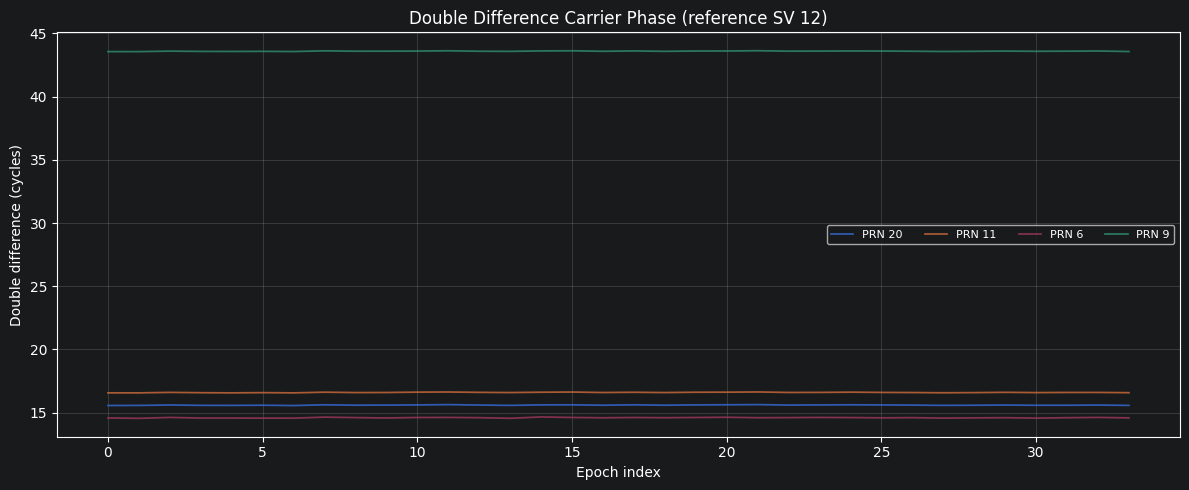

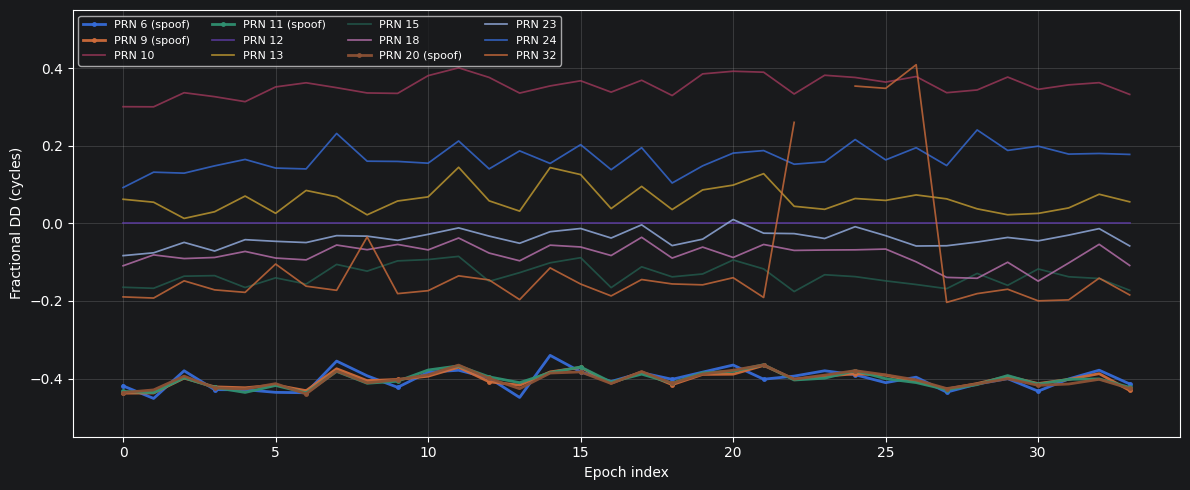

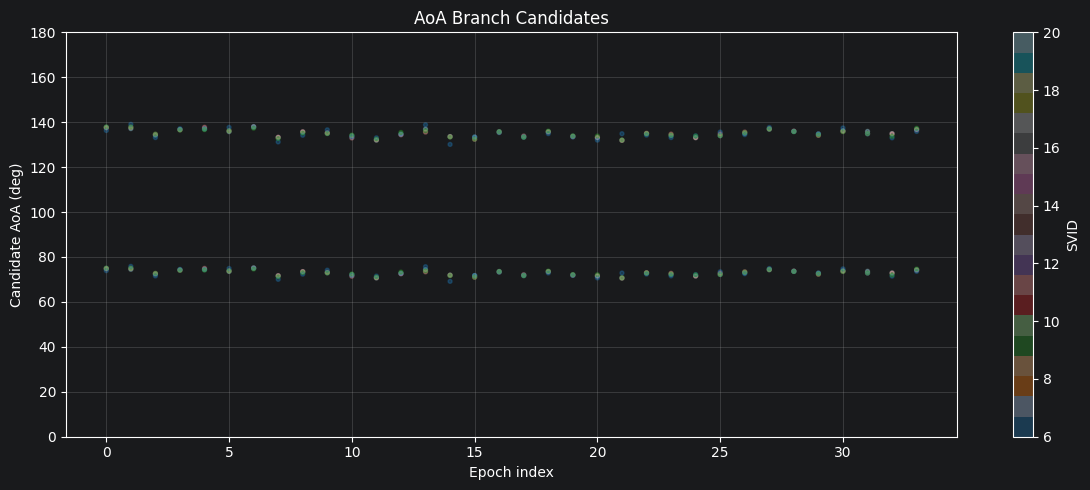

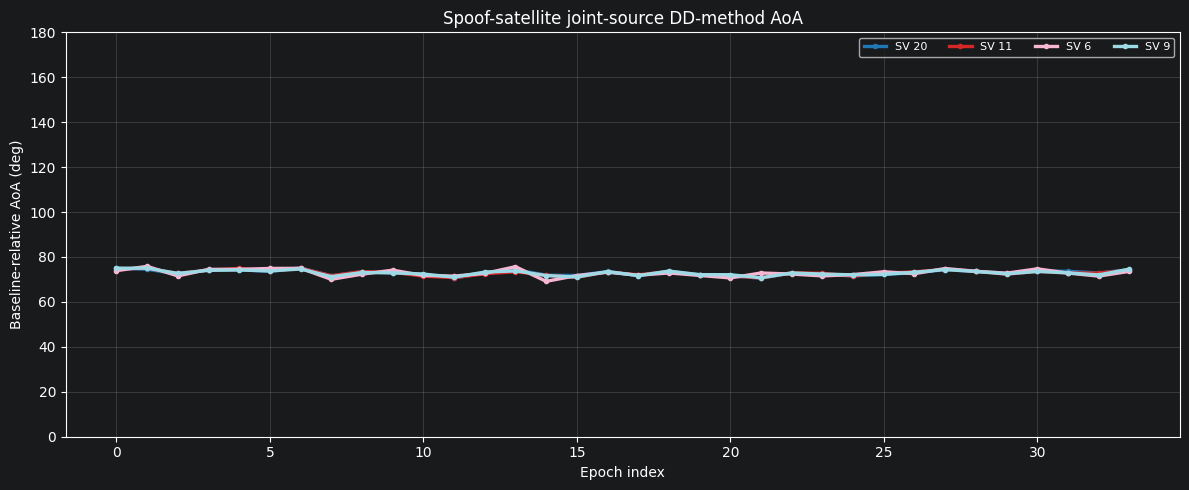

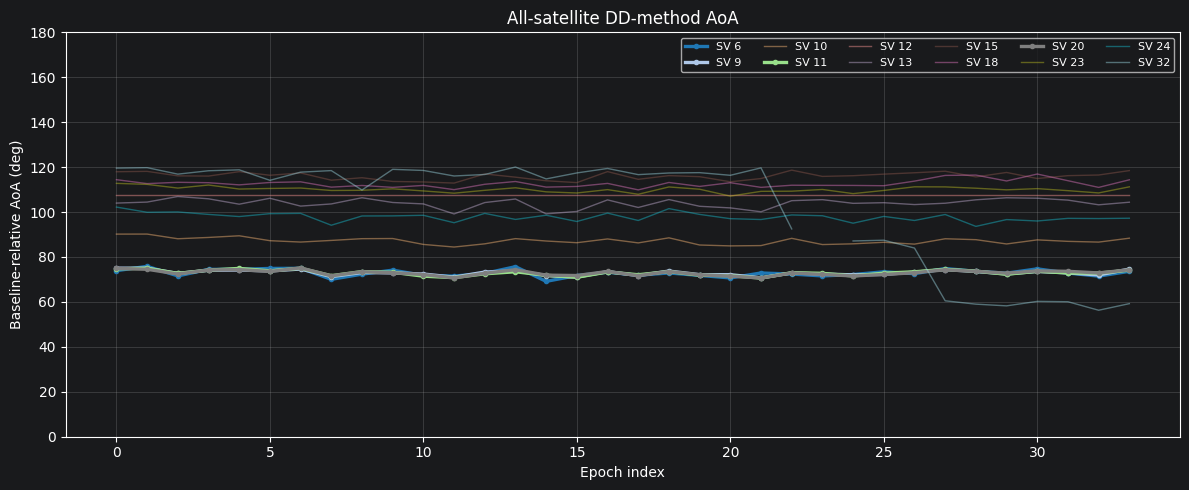

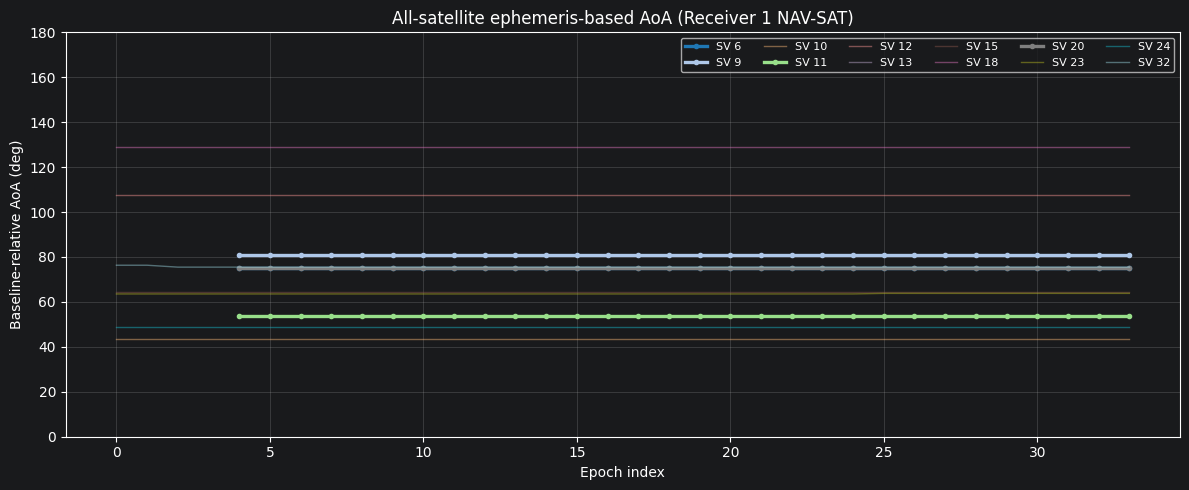

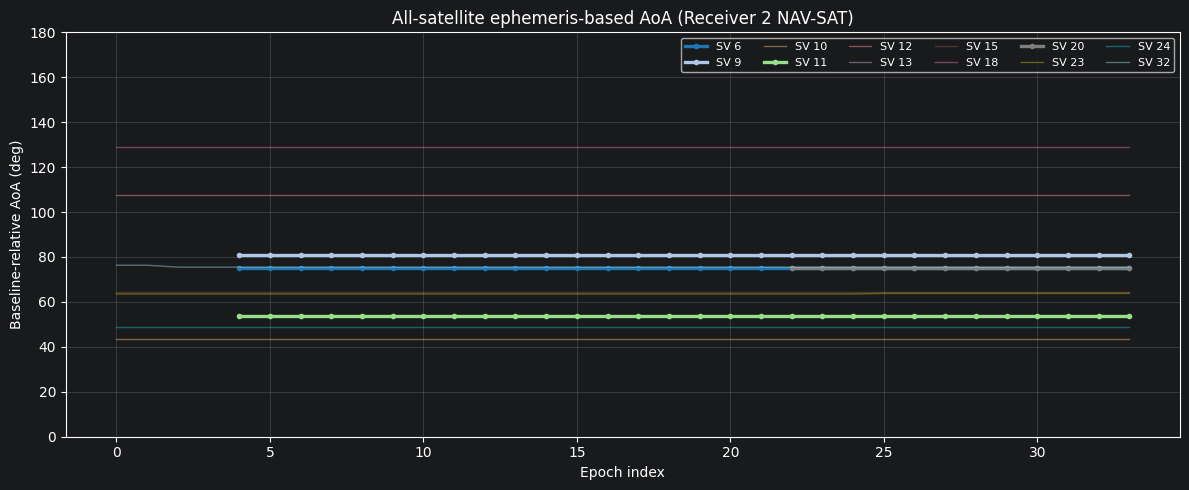

,svid,branch,valid_epoch_count,median_candidate_aoa_deg,mean_candidate_aoa_deg,min_candidate_aoa_deg,max_candidate_aoa_deg,median_candidate_cos_alpha,reference_epoch_count,median_reference_aoa_deg,median_abs_error_to_reference_deg,mean_abs_error_to_reference_deg,within_10deg_fraction,dp_selected_epoch_fraction
0,6,0,34,134.799719,134.961691,130.109753,139.048357,-0.704631,30.0,75.088329,5.961139e+01,5.968124e+01,0.000000,0.000000
1,6,1,34,72.820311,72.905780,69.160817,75.833709,0.295369,30.0,75.088329,2.342397e+00,2.362279e+00,1.000000,1.000000
2,9,0,34,134.937854,135.005098,132.076007,137.870849,-0.706339,30.0,80.670347,5.424724e+01,5.410644e+01,0.000000,0.000000
3,9,1,34,72.922762,72.953450,70.738256,75.026910,0.293661,30.0,80.670347,7.762598e+00,7.883386e+00,1.000000,1.000000
4,10,-1,32,161.499637,161.721541,154.555355,171.990731,-0.948313,32.0,43.500553,1.179991e+02,1.182210e+02,0.000000,0.000000
5,10,0,34,87.188366,87.153185,84.433602,90.201519,0.049053,34.0,43.500553,4.368781e+01,4.365263e+01,0.000000,1.000000
6,10,1,2,4.694549,4.694549,4.582236,4.806863,0.996643,2.0,43.500553,3.880600e+01,3.880600e+01,0.000000,0.000000
7,11,0,34,134.980162,135.006208,131.932421,137.825017,-0.706861,30.0,53.896290,8.096781e+01,8.089467e+01,0.000000,0.000000
8,11,1,34,72.954037,72.952547,70.625192,74.995068,0.293139,30.0,53.896290,1.897180e+01,1.889869e+01,0.000000,1.000000
9,12,0,34,107.694647,107.694647,107.694647,107.694647,-0.303944,34.0,107.694647,1.421085e-14,1.421085e-14,1.000000,1.000000


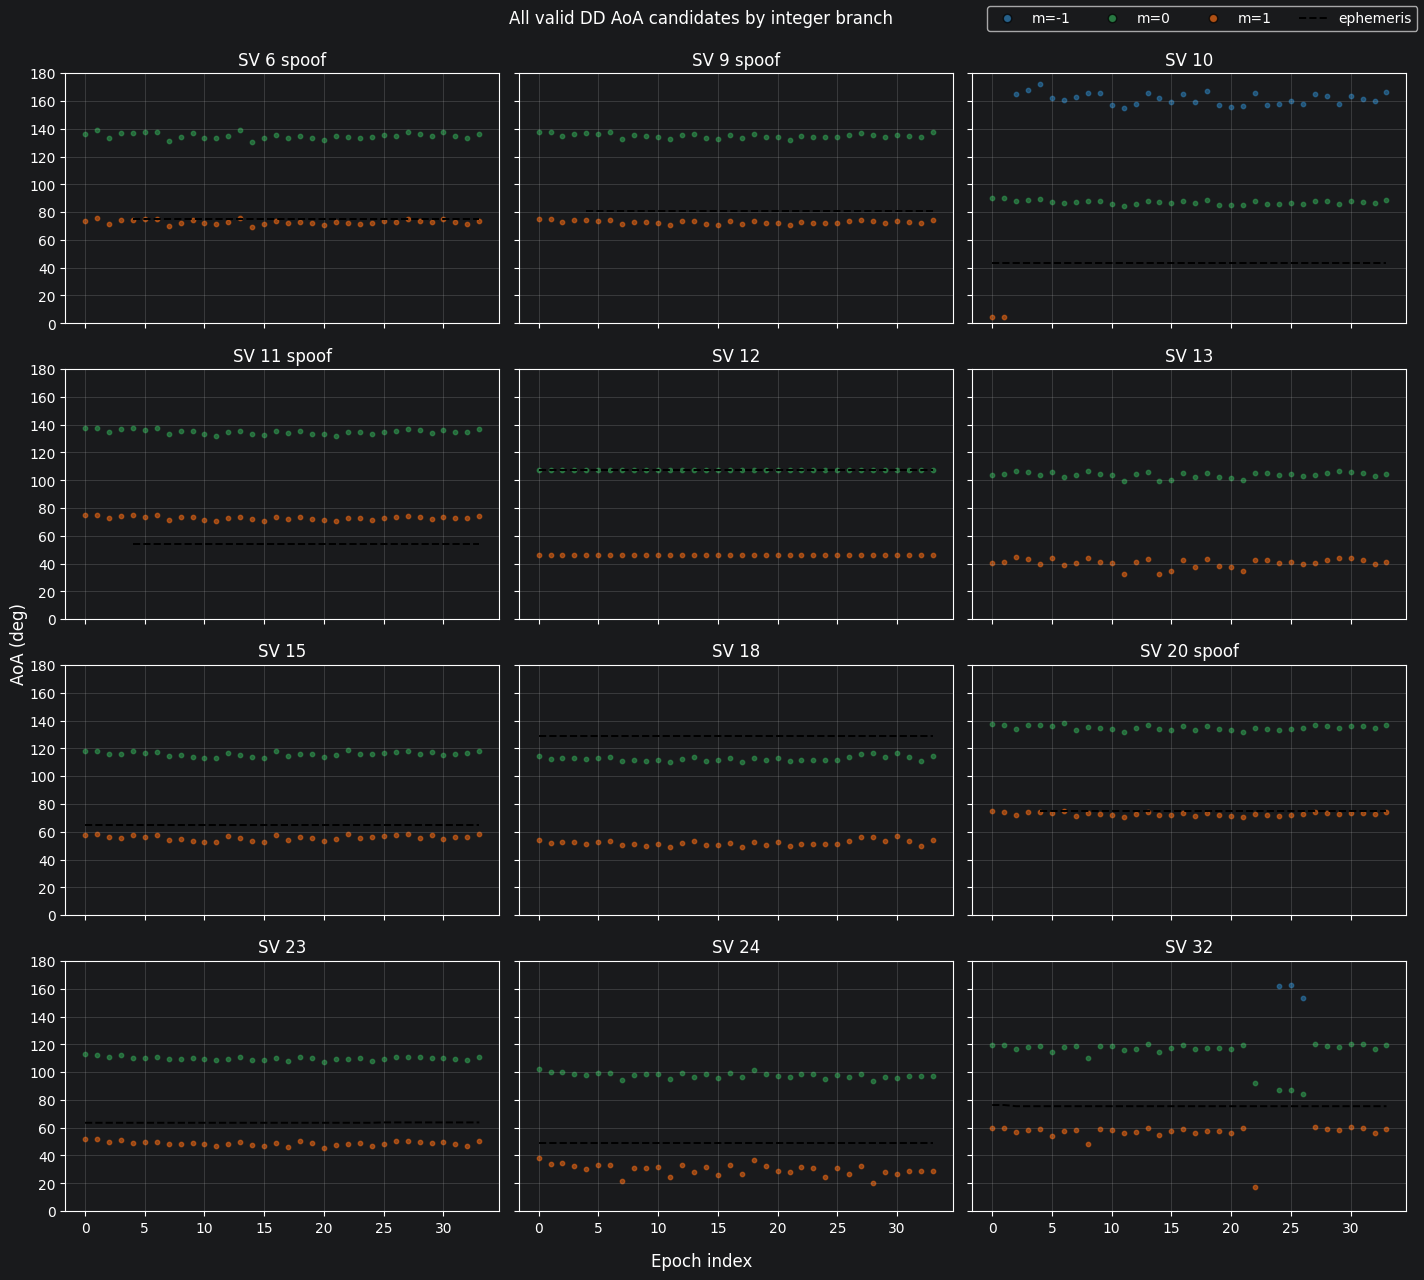

,svid,branch
0,6,1
1,9,1
2,10,0
3,11,1
4,12,0
5,15,1
6,18,0
7,20,1
8,23,1
9,24,1


,method,svid,branch,epoch_count,median_abs_error_deg,mean_abs_error_deg,p90_abs_error_deg,within_5deg_fraction,within_10deg_fraction
0,dp_smoothness,6,1,30,2.342397e+00,2.362279e+00,3.684540e+00,0.933333,1.000000
1,ephemeris_aligned_constant_m,6,1,30,2.342397e+00,2.362279e+00,3.684540e+00,0.933333,1.000000
2,dp_smoothness,9,1,30,7.762598e+00,7.883386e+00,9.430360e+00,0.000000,1.000000
3,ephemeris_aligned_constant_m,9,1,30,7.762598e+00,7.883386e+00,9.430360e+00,0.000000,1.000000
4,dp_smoothness,10,0,34,4.368781e+01,4.365263e+01,4.515016e+01,0.000000,0.000000
5,ephemeris_aligned_constant_m,10,0,34,4.368781e+01,4.365263e+01,4.515016e+01,0.000000,0.000000
6,dp_smoothness,11,1,30,1.897180e+01,1.889869e+01,2.028309e+01,0.000000,0.000000
7,ephemeris_aligned_constant_m,11,1,30,1.897180e+01,1.889869e+01,2.028309e+01,0.000000,0.000000
8,dp_smoothness,12,0,34,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,1.000000
9,ephemeris_aligned_constant_m,12,0,34,1.421085e-14,1.421085e-14,1.421085e-14,1.000000,1.000000


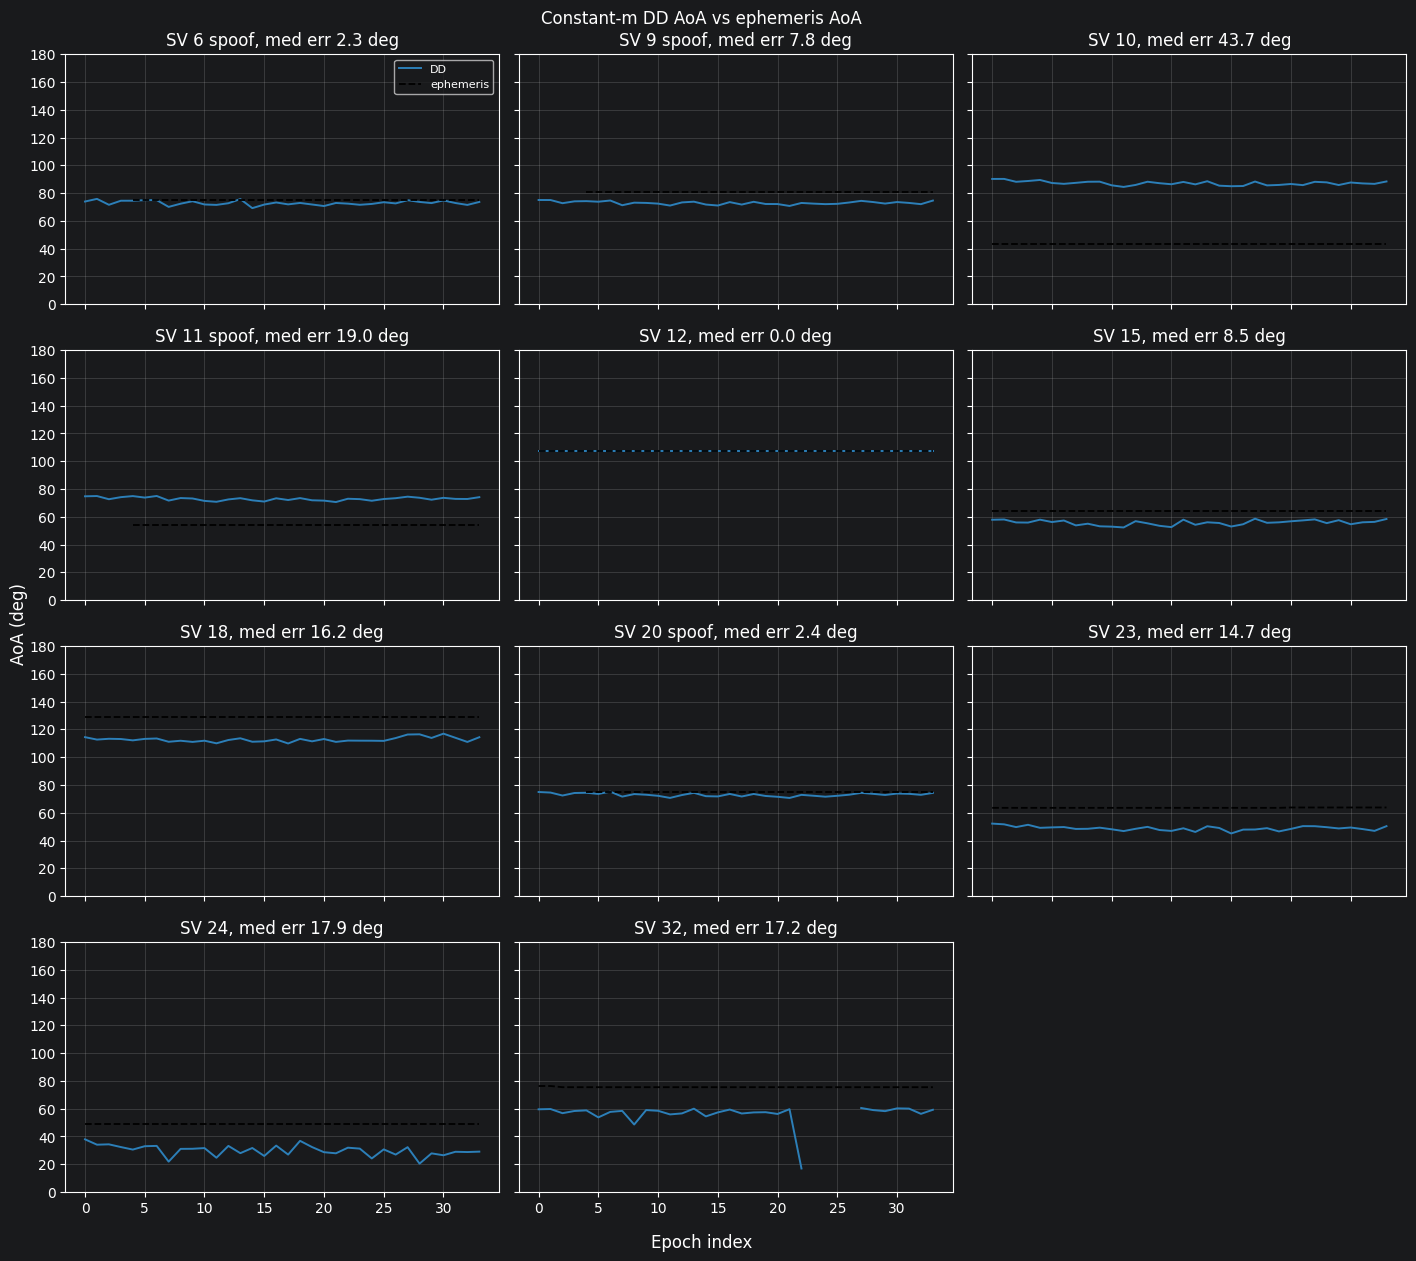

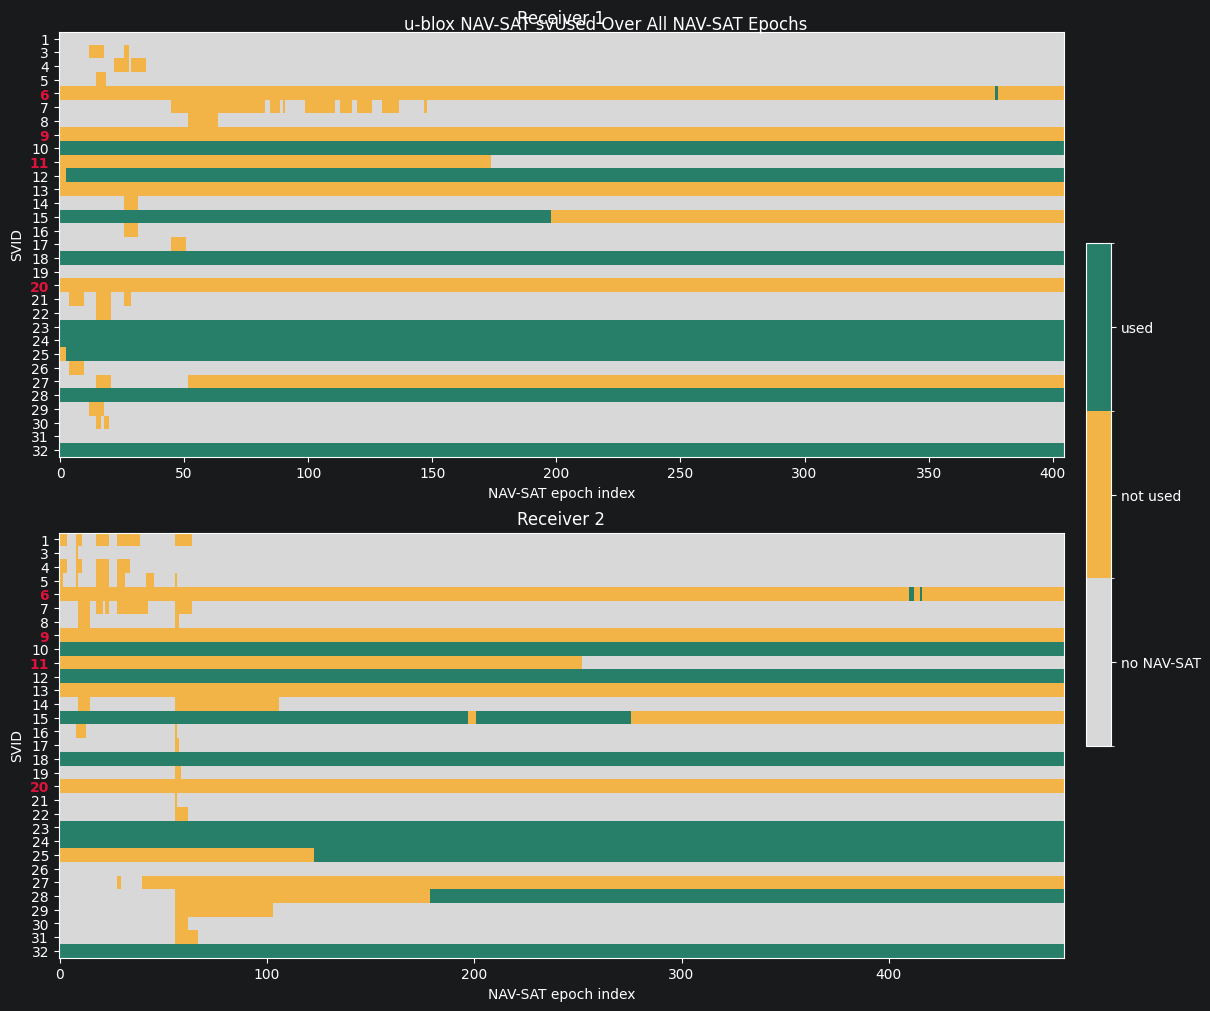

In [254]:
fig = plot_double_difference(result)
display(fig)
plt.close(fig)

fig = plot_fractional_dd(
    all_satellite_result,
    highlight_svids=SPOOF_SVIDS,
    title=None,
)
display(fig)
plt.close(fig)

if not result.candidate_aoa_deg.empty:
    fig = plot_candidate_cloud(result)
    display(fig)
    plt.close(fig)

if PARTIAL_SPOOF_ENABLED:
    fig = plot_aoa_tracks(
        scenario.joint_source_aoa_deg,
        title="Spoof-satellite joint-source DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

if not scenario.all_satellite_dd_method_aoa_deg.empty:
    fig = plot_aoa_tracks(
        scenario.all_satellite_dd_method_aoa_deg,
        title="All-satellite DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

fig = plot_aoa_tracks(
    scenario.ephemeris_aoa_rx1_deg,
    title="All-satellite ephemeris-based AoA (Receiver 1 NAV-SAT)",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

fig = plot_aoa_tracks(
    scenario.ephemeris_aoa_rx2_deg,
    title="All-satellite ephemeris-based AoA (Receiver 2 NAV-SAT)",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)

if not scenario.all_satellite_valid_m_candidates.empty:
    display(scenario.all_satellite_valid_m_summary)
    fig = plot_valid_m_candidates(
        scenario.all_satellite_result.candidate_aoa_deg,
        reference_aoa=scenario.ephemeris_aoa_rx1_deg,
        title="All valid DD AoA candidates by integer branch",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

if not scenario.ephemeris_aligned_dd_method_aoa_deg.empty:
    display(scenario.ephemeris_aligned_branch)
    display(scenario.aoa_method_equivalence_summary)
    fig = plot_aoa_method_comparison(
        scenario.ephemeris_aligned_dd_method_aoa_deg,
        scenario.ephemeris_aoa_rx1_deg,
        title="Constant-m DD AoA vs ephemeris AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

fig = plot_sv_used_timeline(
    {"Receiver 1": scenario.sv_used_rx1, "Receiver 2": scenario.sv_used_rx2},
    title="u-blox NAV-SAT svUsed Over All NAV-SAT Epochs",
    highlight_svids=SPOOF_SVIDS,
)
display(fig)
plt.close(fig)


## All-satellite DD-method AoA with Best-m Branch

The final all-satellite AoA is reconstructed in two groups according to the configured `SPOOF_SVIDS` labels:

- **Authentic SVs** take the branch whose candidate track is closest to the ephemeris AoA (`select_aoa_by_reference` — the "best m" visible in the valid-`m` candidate plot). This fixes branches the DP mis-selects (e.g. SV24/SV25), so genuine satellites stop looking spoofed.
- **Spoof SVs** keep the DP branch on purpose, so their common-source collapse stays intact and the branch is not biased toward the ephemeris under test.
- If an authentic SV has no ephemeris reference, it falls back to DP because a best-`m` branch cannot be selected for that SV.

The first two figures below put the reconstructed DD-method AoA and Receiver 1 ephemeris-method AoA next to each other with the same satellite highlighting, making the per-satellite tracks directly comparable. Frame: `scenario.best_m_all_satellite_aoa_deg`; saved as `paper_all_satellite_dd_method_aoa_best_m.png`.

The diagnostics below compare the best-m DD solution with Receiver 1's ephemeris-based AoA at shared epochs. The signed difference is **DD-method AoA minus ephemeris-based AoA**. The table reports error magnitude per satellite, while the figures show the time-varying signed difference and the absolute-error distribution.


All-satellite DD-method AoA with best-m branch (authentic fixed, spoof kept on DP)


,6,9,10,11,12,13,15,18,20,23,24,32
epoch_index,,,,,,,,,,,,
0,73.916667,75.026910,90.183135,74.762578,107.694647,103.994098,57.904415,114.410656,74.937375,52.201291,37.966908,59.568414
1,75.833709,75.002474,90.201519,74.953326,107.694647,104.442257,58.082824,112.658574,74.528583,51.673528,34.104620,59.768292
2,71.574995,72.718106,88.118013,72.664338,107.694647,106.930311,55.951105,113.246780,72.405415,49.684110,34.364182,56.777876
3,74.494168,74.060980,88.701609,74.157023,107.694647,105.901397,55.851996,113.069863,74.223543,51.339881,32.404110,58.357564
4,74.501960,74.203781,89.441102,74.917428,107.694647,103.506032,57.947771,112.104301,74.387216,49.155597,30.587848,58.788598


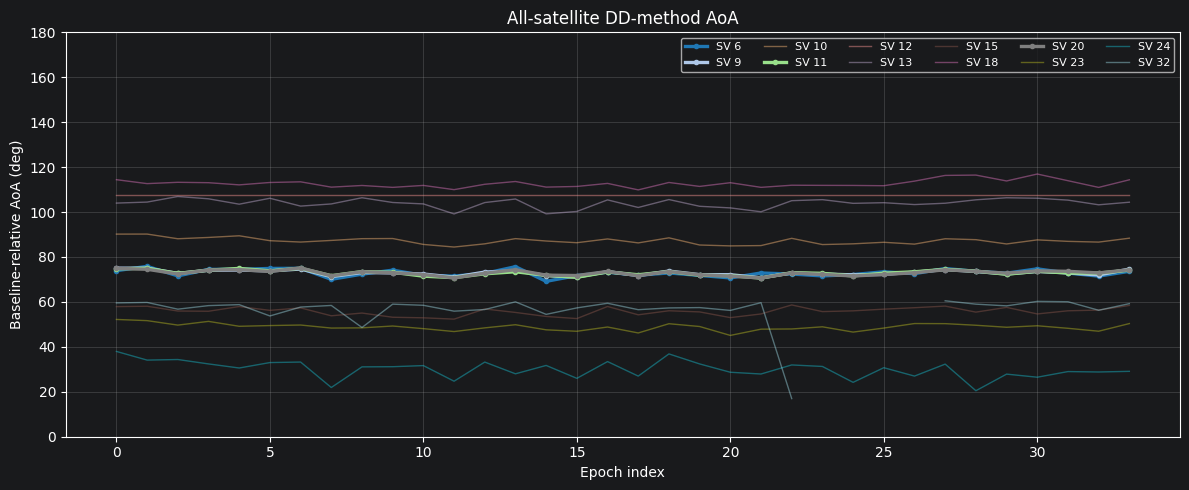

Ephemeris-method AoA for direct per-satellite comparison


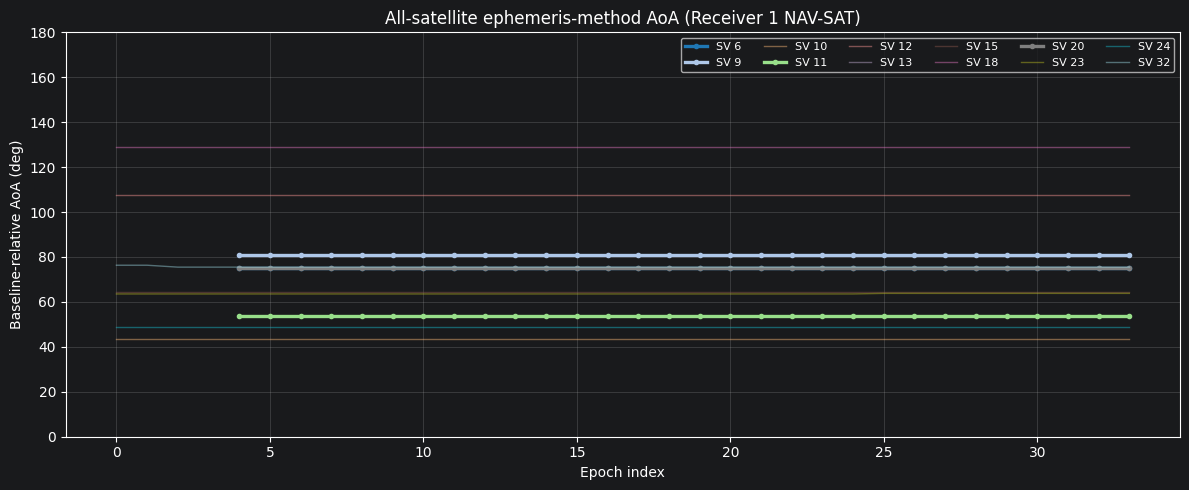

,signal_group,reconstruction_source,matches_source_track
svid,,,
6,spoof,DP,True
9,spoof,DP,True
10,authentic,best-m (ephemeris aligned),True
11,spoof,DP,True
12,authentic,best-m (ephemeris aligned),True
13,authentic,DP fallback (no ephemeris),True
15,authentic,best-m (ephemeris aligned),True
18,authentic,best-m (ephemeris aligned),True
20,spoof,DP,True


,signal_type,epoch_count,bias_deg,mae_deg,median_abs_error_deg,rmse_deg,p90_abs_error_deg,max_abs_error_deg,within_5deg_pct,within_10deg_pct
svid,,,,,,,,,,
6,spoof,30,-2.32,2.36,2.34,2.76,3.68,5.93,93.33,100.00
9,spoof,30,-7.88,7.88,7.76,7.96,9.43,9.93,0.00,100.00
10,authentic,34,43.65,43.65,43.69,43.68,45.15,46.70,0.00,0.00
11,spoof,30,18.90,18.90,18.97,18.93,20.28,21.10,0.00,0.00
12,authentic,34,0.00,0.00,0.00,0.00,0.00,0.00,100.00,100.00
13,authentic,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,authentic,34,-8.70,8.70,8.52,8.88,11.45,12.17,0.00,76.47
18,authentic,34,-16.05,16.05,16.23,16.14,17.75,18.88,0.00,0.00
20,spoof,30,-2.44,2.44,2.39,2.69,3.72,4.62,100.00,100.00


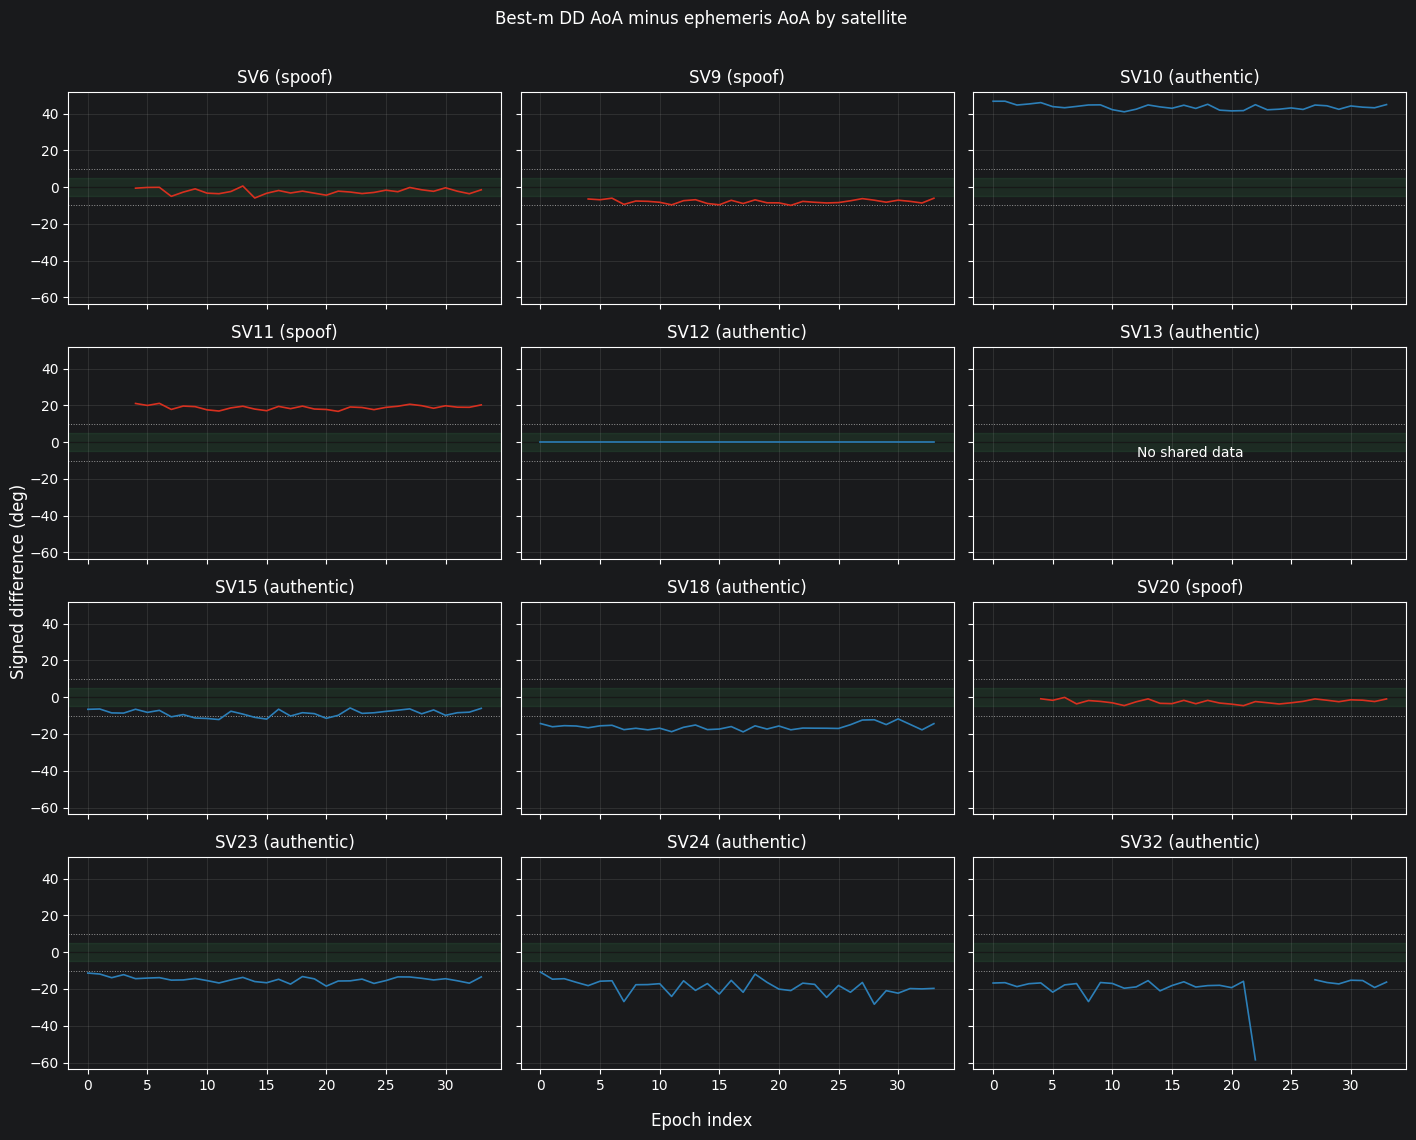

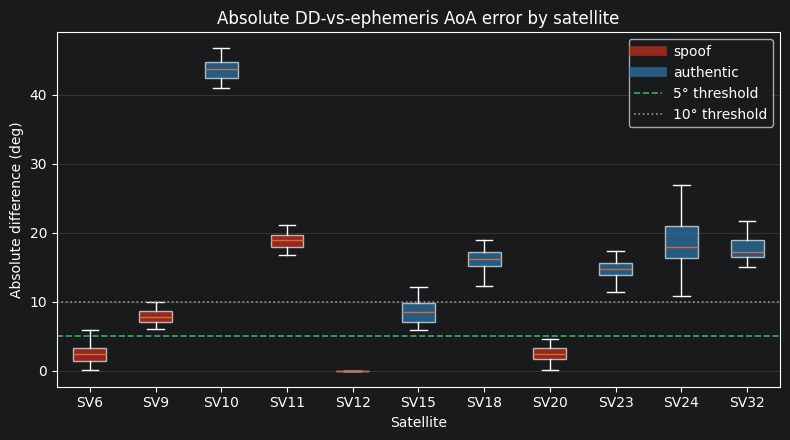

In [255]:
if not scenario.best_m_all_satellite_aoa_deg.empty:
    print("All-satellite DD-method AoA with best-m branch (authentic fixed, spoof kept on DP)")
    display(scenario.best_m_all_satellite_aoa_deg.head())
    fig = plot_aoa_tracks(
        scenario.best_m_all_satellite_aoa_deg,
        title="All-satellite DD-method AoA",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

    print("Ephemeris-method AoA for direct per-satellite comparison")
    fig = plot_aoa_tracks(
        scenario.ephemeris_aoa_rx1_deg,
        title="All-satellite ephemeris-method AoA (Receiver 1 NAV-SAT)",
        highlight_svids=SPOOF_SVIDS,
    )
    display(fig)
    plt.close(fig)

    # Confirm which source reconstructs each final satellite track.
    reconstruction_rows = []
    ephemeris_aligned_svids = set(map(int, scenario.ephemeris_aligned_dd_method_aoa_deg.columns))
    for svid in map(int, scenario.best_m_all_satellite_aoa_deg.columns):
        use_dp = svid in SPOOF_SVIDS or svid not in ephemeris_aligned_svids
        source_frame = (
            scenario.all_satellite_dd_method_aoa_deg
            if use_dp
            else scenario.ephemeris_aligned_dd_method_aoa_deg
        )
        final_track = scenario.best_m_all_satellite_aoa_deg[svid]
        expected_track = source_frame[svid].reindex(final_track.index)
        reconstruction_rows.append(
            {
                "svid": svid,
                "signal_group": "spoof" if svid in SPOOF_SVIDS else "authentic",
                "reconstruction_source": (
                    "DP" if svid in SPOOF_SVIDS else "DP fallback (no ephemeris)"
                ) if use_dp else "best-m (ephemeris aligned)",
                "matches_source_track": final_track.equals(expected_track),
            }
        )
    reconstruction_confirmation = pd.DataFrame(reconstruction_rows).set_index("svid")
    assert reconstruction_confirmation["matches_source_track"].all()
    display(reconstruction_confirmation)

    # Compare only shared satellites and epochs; signed error = DD method - ephemeris.
    shared_svids = sorted(
        set(map(int, scenario.best_m_all_satellite_aoa_deg.columns))
        & set(map(int, scenario.ephemeris_aoa_rx1_deg.columns))
    )
    best_m_dd = scenario.best_m_all_satellite_aoa_deg.reindex(columns=shared_svids)
    ephemeris = scenario.ephemeris_aoa_rx1_deg.reindex(columns=shared_svids)
    dd_ephemeris_diff_deg = best_m_dd.subtract(ephemeris)

    error_rows = []
    for svid in shared_svids:
        signed_error = dd_ephemeris_diff_deg[svid].dropna()
        abs_error = signed_error.abs()
        error_rows.append(
            {
                "svid": svid,
                "signal_type": "spoof" if svid in SPOOF_SVIDS else "authentic",
                "epoch_count": len(signed_error),
                "bias_deg": signed_error.mean(),
                "mae_deg": abs_error.mean(),
                "median_abs_error_deg": abs_error.median(),
                "rmse_deg": (signed_error.pow(2).mean()) ** 0.5,
                "p90_abs_error_deg": abs_error.quantile(0.90),
                "max_abs_error_deg": abs_error.max(),
                "within_5deg_pct": 100 * abs_error.le(5).mean(),
                "within_10deg_pct": 100 * abs_error.le(10).mean(),
            }
        )

    dd_ephemeris_error_summary = pd.DataFrame(error_rows).set_index("svid")
    display(dd_ephemeris_error_summary.round(2))

    output_dir = SCENARIO_CONFIG.output_dir
    dd_ephemeris_diff_deg.to_csv(output_dir / "paper_best_m_dd_minus_ephemeris_deg.csv", index=True)
    dd_ephemeris_error_summary.to_csv(
        output_dir / "paper_best_m_dd_vs_ephemeris_error_summary.csv", index=True
    )

    ncols = min(3, len(shared_svids))
    nrows = (len(shared_svids) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4.8 * ncols, 2.8 * nrows), sharex=True, sharey=True
    )
    axes = [axes] if nrows * ncols == 1 else axes.ravel()
    for ax, svid in zip(axes, shared_svids):
        color = "#d7301f" if svid in SPOOF_SVIDS else "#2c7fb8"
        ax.axhspan(-5, 5, color="#41ab5d", alpha=0.12, label="within ±5°")
        ax.axhline(0, color="black", lw=0.8, zorder=1)
        ax.axhline(10, color="#969696", lw=0.7, ls=":")
        ax.axhline(-10, color="#969696", lw=0.7, ls=":")
        if dd_ephemeris_diff_deg[svid].notna().any():
            ax.plot(
                dd_ephemeris_diff_deg.index, dd_ephemeris_diff_deg[svid],
                color=color, lw=1.2, zorder=2,
            )
        else:
            ax.text(0.5, 0.5, "No shared data", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(f"SV{svid} ({'spoof' if svid in SPOOF_SVIDS else 'authentic'})")
        ax.grid(alpha=0.2)
    for ax in axes[len(shared_svids):]:
        ax.axis("off")
    fig.suptitle("Best-m DD AoA minus ephemeris AoA by satellite", y=1.01)
    fig.supxlabel("Epoch index")
    fig.supylabel("Signed difference (deg)")
    fig.tight_layout()
    fig.savefig(
        output_dir / "paper_best_m_dd_minus_ephemeris_by_satellite.png",
        dpi=180, bbox_inches="tight",
    )
    display(fig)
    plt.close(fig)

    plotted_svids = [svid for svid in shared_svids if dd_ephemeris_diff_deg[svid].notna().any()]
    error_series = [dd_ephemeris_diff_deg[svid].dropna().abs() for svid in plotted_svids]
    fig, ax = plt.subplots(figsize=(max(8, 0.65 * len(plotted_svids)), 4.5))
    boxes = ax.boxplot(error_series, tick_labels=[f"SV{svid}" for svid in plotted_svids], showfliers=False, patch_artist=True)
    for box, svid in zip(boxes["boxes"], plotted_svids):
        box.set_facecolor("#d7301f" if svid in SPOOF_SVIDS else "#2c7fb8")
        box.set_alpha(0.65)
    ax.plot([], [], color="#d7301f", lw=7, alpha=0.65, label="spoof")
    ax.plot([], [], color="#2c7fb8", lw=7, alpha=0.65, label="authentic")
    ax.axhline(5, color="#41ab5d", lw=1.2, ls="--", label="5° threshold")
    ax.axhline(10, color="#969696", lw=1.2, ls=":", label="10° threshold")
    ax.set_title("Absolute DD-vs-ephemeris AoA error by satellite")
    ax.set_xlabel("Satellite")
    ax.set_ylabel("Absolute difference (deg)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        output_dir / "paper_best_m_dd_vs_ephemeris_absolute_error.png",
        dpi=180, bbox_inches="tight",
    )
    display(fig)
    plt.close(fig)


## Pairwise Threshold Classifier: Journal Baseline

This section preserves the current journal method as the comparison baseline. It applies the manuscript's median-over-epochs Eq. (32) residual to the configured fixed-reference hybrid best-m reconstruction. Authentic signals use ephemeris-aligned constant best-m, while counterfeit signals retain DP so the known common-source collapse is preserved. This label-dependent branch treatment is intentionally retained as a scenario-specific diagnostic, not a blind deployable detector.

The residual is computed in the direction-cosine domain exactly as defined by manuscript Eq. (32). Because no independent authentic calibration recording is currently available, automatic label-based threshold tuning is not used. The code instead exposes one manual constant, HARD_CODED_PAIRWISE_THRESHOLD = 0.20. Change that constant to test another operating point.

The score threshold remains fixed at $\eta=0.5$. The hard-coded $\tau_q$ is unitless because it thresholds direction-cosine residuals. The diagnostics report every threshold interval and its resulting PRN groups, but they do not select a threshold automatically.

For interpretability, the diagnostics list every consistent and inconsistent partner of each PRN. In the journal baseline, a pair is consistent exactly when its aggregated Eq. (32) residual satisfies $q_{ij} \leq \tau_q$; the satellite score is the number of consistent partners divided by all available partners. The following section adds the minimal common-direction penalty requested here while retaining this baseline unchanged for a direct before-and-after comparison.

A fixed DD reference has no DD reconstruction of itself and is consequently excluded from a single-reference run, leaving ten classified targets and nine possible partners per target. Filling the manuscript's 11-satellite Table 3 requires the multiple-reference aggregation reported below.


,svid,consistent_pair_count,valid_pair_count,possible_pair_count,pair_coverage,consistency_score,available_pair_score,pairwise_threshold,score_threshold,decision,ground_truth,correct
4,6,5,9,9,1.0,0.555556,0.555556,0.2,0.5,Authentic,Counterfeit,False
0,9,7,9,9,1.0,0.777778,0.777778,0.2,0.5,Authentic,Counterfeit,False
8,10,0,9,9,1.0,0.000000,0.000000,0.2,0.5,Counterfeit,Authentic,False
9,11,0,9,9,1.0,0.000000,0.000000,0.2,0.5,Counterfeit,Counterfeit,True
1,15,7,9,9,1.0,0.777778,0.777778,0.2,0.5,Authentic,Authentic,True
5,18,5,9,9,1.0,0.555556,0.555556,0.2,0.5,Authentic,Authentic,True
6,20,5,9,9,1.0,0.555556,0.555556,0.2,0.5,Authentic,Counterfeit,False
2,23,7,9,9,1.0,0.777778,0.777778,0.2,0.5,Authentic,Authentic,True
3,24,7,9,9,1.0,0.777778,0.777778,0.2,0.5,Authentic,Authentic,True
7,32,5,9,9,1.0,0.555556,0.555556,0.2,0.5,Authentic,Authentic,True


,svid,ground_truth,median_signed_geometry_error,consistent_pair_count,possible_pair_count,consistency_score,consistent_with,inconsistent_with,score_decision_reason,decision,correct
0,6,Counterfeit,0.0393,5,9,0.5556,PRN 20 (q=0.0092); PRN 15 (q=0.0908); PRN 9 (q=0.0952); PRN 24 (q=0.1781); PRN 23 (q=0.1815),PRN 18 (q=0.2051); PRN 32 (q=0.2397); PRN 11 (q=0.3332); PRN 10 (q=0.7081),5/9=0.556 >= eta=0.500,Authentic,False
1,9,Counterfeit,0.1318,7,9,0.7778,PRN 15 (q=0.0152); PRN 24 (q=0.0739); PRN 23 (q=0.0863); PRN 20 (q=0.0915); PRN 6 (q=0.0952); PRN 18 (q=0.1134); PRN 32 (q=0.1451),PRN 11 (q=0.4285); PRN 10 (q=0.8057),7/9=0.778 >= eta=0.500,Authentic,False
2,10,Authentic,-0.6763,0,9,0.0000,None,PRN 11 (q=0.3772); PRN 6 (q=0.7081); PRN 20 (q=0.7112); PRN 9 (q=0.8057); PRN 15 (q=0.8087); PRN 24 (q=0.8807); PRN 23 (q=0.8933); PRN 18 (q=0.9157); PRN 32 (q=0.9526),0/9=0.000 < eta=0.500,Counterfeit,False
3,11,Counterfeit,-0.2947,0,9,0.0000,None,PRN 6 (q=0.3332); PRN 20 (q=0.3348); PRN 10 (q=0.3772); PRN 9 (q=0.4285); PRN 15 (q=0.4310); PRN 24 (q=0.5055); PRN 23 (q=0.5136); PRN 18 (q=0.5382); PRN 32 (q=0.5719),0/9=0.000 < eta=0.500,Counterfeit,True
4,15,Authentic,0.1290,7,9,0.7778,PRN 9 (q=0.0152); PRN 24 (q=0.0729); PRN 23 (q=0.0776); PRN 6 (q=0.0908); PRN 20 (q=0.0953); PRN 18 (q=0.1115); PRN 32 (q=0.1550),PRN 11 (q=0.4310); PRN 10 (q=0.8087),7/9=0.778 >= eta=0.500,Authentic,True
5,18,Authentic,0.2430,5,9,0.5556,PRN 23 (q=0.0305); PRN 32 (q=0.0437); PRN 24 (q=0.0534); PRN 15 (q=0.1115); PRN 9 (q=0.1134),PRN 20 (q=0.2034); PRN 6 (q=0.2051); PRN 11 (q=0.5382); PRN 10 (q=0.9157),5/9=0.556 >= eta=0.500,Authentic,True
6,20,Counterfeit,0.0401,5,9,0.5556,PRN 6 (q=0.0092); PRN 9 (q=0.0915); PRN 15 (q=0.0953); PRN 24 (q=0.1711); PRN 23 (q=0.1784),PRN 18 (q=0.2034); PRN 32 (q=0.2352); PRN 11 (q=0.3348); PRN 10 (q=0.7112),5/9=0.556 >= eta=0.500,Authentic,False
7,23,Authentic,0.2121,7,9,0.7778,PRN 24 (q=0.0238); PRN 18 (q=0.0305); PRN 32 (q=0.0612); PRN 15 (q=0.0776); PRN 9 (q=0.0863); PRN 20 (q=0.1784); PRN 6 (q=0.1815),PRN 11 (q=0.5136); PRN 10 (q=0.8933),7/9=0.778 >= eta=0.500,Authentic,True
8,24,Authentic,0.1989,7,9,0.7778,PRN 23 (q=0.0238); PRN 18 (q=0.0534); PRN 15 (q=0.0729); PRN 9 (q=0.0739); PRN 32 (q=0.0815); PRN 20 (q=0.1711); PRN 6 (q=0.1781),PRN 11 (q=0.5055); PRN 10 (q=0.8807),7/9=0.778 >= eta=0.500,Authentic,True
9,32,Authentic,0.2748,5,9,0.5556,PRN 18 (q=0.0437); PRN 23 (q=0.0612); PRN 24 (q=0.0815); PRN 9 (q=0.1451); PRN 15 (q=0.1550),PRN 20 (q=0.2352); PRN 6 (q=0.2397); PRN 11 (q=0.5719); PRN 10 (q=0.9526),5/9=0.556 >= eta=0.500,Authentic,True


,left_svid,right_svid,residual_domain,residual_unit,aggregated_pairwise_residual,min_reference_residual,max_reference_residual,reference_count,epoch_observation_count,pair,median_measured_relative_direction_cosine,median_expected_relative_direction_cosine,left_median_signed_geometry_error,right_median_signed_geometry_error,median_signed_error_separation,left_ground_truth,right_ground_truth,pair_type,consistent,threshold_margin,consistency_reason
0,6,20,direction_cosine,direction_cosine,0.0092,0.0092,0.0092,1,30,PRN 6–PRN 20,0.0021,0.0032,0.0393,0.0401,0.0008,Counterfeit,Counterfeit,counterfeit-counterfeit,True,0.1908,q=0.0092 <= tau=0.2000
12,6,15,direction_cosine,direction_cosine,0.0908,0.0908,0.0908,1,30,PRN 6–PRN 15,-0.2638,-0.1730,0.0393,0.1290,0.0897,Counterfeit,Authentic,mixed,True,0.1092,q=0.0908 <= tau=0.2000
14,6,9,direction_cosine,direction_cosine,0.0952,0.0952,0.0952,1,30,PRN 6–PRN 9,0.0000,0.0952,0.0393,0.1318,0.0925,Counterfeit,Counterfeit,counterfeit-counterfeit,True,0.1048,q=0.0952 <= tau=0.2000
21,6,24,direction_cosine,direction_cosine,0.1781,0.1781,0.1781,1,30,PRN 6–PRN 24,-0.5798,-0.4017,0.0393,0.1989,0.1597,Counterfeit,Authentic,mixed,True,0.0219,q=0.1781 <= tau=0.2000
23,6,23,direction_cosine,direction_cosine,0.1815,0.1815,0.1815,1,30,PRN 6–PRN 23,-0.3684,-0.1882,0.0393,0.2121,0.1729,Counterfeit,Authentic,mixed,True,0.0185,q=0.1815 <= tau=0.2000
1,9,15,direction_cosine,direction_cosine,0.0152,0.0152,0.0152,1,30,PRN 9–PRN 15,-0.2668,-0.2682,0.1318,0.1290,0.0028,Counterfeit,Authentic,mixed,True,0.1848,q=0.0152 <= tau=0.2000
8,9,24,direction_cosine,direction_cosine,0.0739,0.0739,0.0739,1,30,PRN 9–PRN 24,-0.5708,-0.4969,0.1318,0.1989,0.0671,Counterfeit,Authentic,mixed,True,0.1261,q=0.0739 <= tau=0.2000
11,9,23,direction_cosine,direction_cosine,0.0863,0.0863,0.0863,1,30,PRN 9–PRN 23,-0.3669,-0.2834,0.1318,0.2121,0.0803,Counterfeit,Authentic,mixed,True,0.1137,q=0.0863 <= tau=0.2000
13,9,20,direction_cosine,direction_cosine,0.0915,0.0915,0.0915,1,30,PRN 9–PRN 20,-0.0005,-0.0921,0.1318,0.0401,0.0917,Counterfeit,Counterfeit,counterfeit-counterfeit,True,0.1085,q=0.0915 <= tau=0.2000
17,9,18,direction_cosine,direction_cosine,0.1134,0.1134,0.1134,1,30,PRN 9–PRN 18,0.6746,0.7880,0.1318,0.2430,0.1112,Counterfeit,Authentic,mixed,True,0.0866,q=0.1134 <= tau=0.2000


,tau_p_direction_cosine,eta,authentic_correct,authentic_total,authentic_acceptance_pct,counterfeit_correct,counterfeit_total,counterfeit_detection_pct,minimum_class_accuracy_pct,balanced_accuracy_pct,overall_correct,overall_total,overall_accuracy_pct,hard_coded_threshold
0,0.0046,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
1,0.0122,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
2,0.0195,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
3,0.0271,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
4,0.0371,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
5,0.0486,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
6,0.0573,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
7,0.0670,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
8,0.0734,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False
9,0.0757,0.5,0,6,0.0000,4,4,100.0,0.0000,50.0000,4,10,40.0,False


,tau_p_direction_cosine,eta,authentic_correct,authentic_total,authentic_acceptance_pct,counterfeit_correct,counterfeit_total,counterfeit_detection_pct,minimum_class_accuracy_pct,balanced_accuracy_pct,overall_correct,overall_total,overall_accuracy_pct,hard_coded_threshold,method,reference_svid,residual_domain,threshold_mode,hard_coded_tau_q,best_fixed_tau_overall_correct_across_eta,score_threshold_change_improves_overall
0,0.2,0.5,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,True,hybrid_best_m,12,direction_cosine,hard_coded,0.2,6,False


,tau_p_direction_cosine,eta,authentic_correct,authentic_total,authentic_acceptance_pct,counterfeit_correct,counterfeit_total,counterfeit_detection_pct,minimum_class_accuracy_pct,balanced_accuracy_pct,overall_correct,overall_total,overall_accuracy_pct,current_score_threshold
0,0.2,0.0000,6,6,100.0000,0,4,0.0,0.0,50.0000,6,10,60.0,False
1,0.2,0.0556,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
2,0.2,0.1111,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
3,0.2,0.1667,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
4,0.2,0.2222,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
5,0.2,0.2778,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
6,0.2,0.3333,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
7,0.2,0.3889,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
8,0.2,0.4444,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,False
9,0.2,0.5000,5,6,83.3333,1,4,25.0,25.0,54.1667,6,10,60.0,True


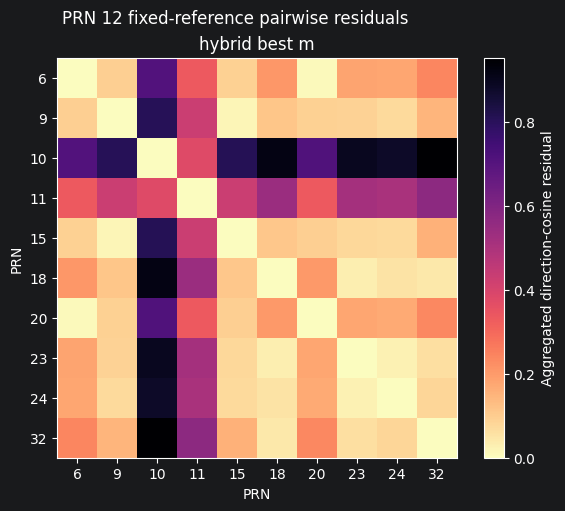

In [256]:
AUTHENTIC_SVIDS = (10, 12, 15, 18, 23, 24, 32)
PAPER_SVIDS = tuple(sorted((*SPOOF_SVIDS, *AUTHENTIC_SVIDS)))
assert set(SPOOF_SVIDS).isdisjoint(AUTHENTIC_SVIDS)
GROUND_TRUTH_BY_SVID = {
    svid: ("Counterfeit" if svid in SPOOF_SVIDS else "Authentic")
    for svid in PAPER_SVIDS
}

# Manual operating value. Change this constant to inspect another tau_q.
HARD_CODED_PAIRWISE_THRESHOLD = 0.20

def geometry_tracks_from_wide(dd_aoa_deg, method):
    target_svids = [
        svid for svid in PAPER_SVIDS
        if svid != HARDCODED_REFERENCE_SVID
        and svid in dd_aoa_deg.columns
        and svid in scenario.ephemeris_aoa_rx1_deg.columns
    ]
    dd_long = (
        dd_aoa_deg.reindex(columns=target_svids)
        .rename_axis(index="epoch_index", columns="svid")
        .stack(future_stack=True).rename("dd_aoa_deg").reset_index()
    )
    eph_long = (
        scenario.ephemeris_aoa_rx1_deg.reindex(columns=target_svids)
        .rename_axis(index="epoch_index", columns="svid")
        .stack(future_stack=True).rename("ephemeris_aoa_deg").reset_index()
    )
    tracks = dd_long.merge(eph_long, on=["epoch_index", "svid"], how="inner").dropna()
    tracks.insert(0, "reference_svid", HARDCODED_REFERENCE_SVID)
    tracks.insert(1, "branch_selection_method", method)
    tracks["dd_direction_cosine"] = np.cos(np.deg2rad(tracks["dd_aoa_deg"]))
    tracks["ephemeris_direction_cosine"] = np.cos(np.deg2rad(tracks["ephemeris_aoa_deg"]))
    tracks["signed_geometry_error"] = (
        tracks["dd_direction_cosine"] - tracks["ephemeris_direction_cosine"]
    )
    return tracks

def attach_ground_truth(scores):
    scores = scores.copy()
    scores["ground_truth"] = scores["svid"].map(GROUND_TRUTH_BY_SVID)
    assert scores["ground_truth"].notna().all()
    scores["correct"] = scores["decision"].eq(scores["ground_truth"])
    return scores

def summarize_labelled_scores(scores, tau_p, eta):
    labelled = attach_ground_truth(scores)
    authentic = labelled[labelled["ground_truth"].eq("Authentic")]
    counterfeit = labelled[labelled["ground_truth"].eq("Counterfeit")]
    authentic_rate = authentic["correct"].mean()
    counterfeit_rate = counterfeit["correct"].mean()
    return {
        "tau_p_direction_cosine": float(tau_p),
        "eta": float(eta),
        "authentic_correct": int(authentic["correct"].sum()),
        "authentic_total": len(authentic),
        "authentic_acceptance_pct": 100 * authentic_rate,
        "counterfeit_correct": int(counterfeit["correct"].sum()),
        "counterfeit_total": len(counterfeit),
        "counterfeit_detection_pct": 100 * counterfeit_rate,
        "minimum_class_accuracy_pct": 100 * min(authentic_rate, counterfeit_rate),
        "balanced_accuracy_pct": 50 * (authentic_rate + counterfeit_rate),
        "overall_correct": int(labelled["correct"].sum()),
        "overall_total": len(labelled),
        "overall_accuracy_pct": 100 * labelled["correct"].mean(),
    }

def score_threshold_candidates(possible_pair_count):
    score_levels = np.arange(possible_pair_count + 1) / possible_pair_count
    midpoints = (score_levels[:-1] + score_levels[1:]) / 2.0
    return np.unique(np.concatenate((score_levels, midpoints)))

def scenario_threshold_candidates(aggregated):
    values = np.sort(aggregated["aggregated_pairwise_residual"].dropna().unique())
    if len(values) == 0:
        raise ValueError("No pairwise residuals are available for threshold selection.")
    lower = max(0.0, float(values[0]) / 2.0)
    midpoints = (values[:-1] + values[1:]) / 2.0
    upper_gap = float(values[-1] - values[-2]) if len(values) > 1 else max(float(values[-1]), 1.0)
    upper = float(values[-1]) + upper_gap / 2.0
    return np.concatenate(([lower], midpoints, [upper]))

def evaluate_pairwise_thresholds(aggregated):
    rows = []
    candidates = np.unique(
        np.append(
            scenario_threshold_candidates(aggregated),
            HARD_CODED_PAIRWISE_THRESHOLD,
        )
    )
    for tau_p in candidates:
        candidate_scores, _, _ = classify_pairwise_geometry(
            aggregated,
            pairwise_threshold=float(tau_p),
            score_threshold=SCORE_THRESHOLD,
            min_pair_coverage=1.0,
        )
        metrics = summarize_labelled_scores(candidate_scores, tau_p, SCORE_THRESHOLD)
        metrics["hard_coded_threshold"] = bool(
            np.isclose(tau_p, HARD_CODED_PAIRWISE_THRESHOLD)
        )
        rows.append(metrics)
    return pd.DataFrame(rows).sort_values(
        "tau_p_direction_cosine"
    ).reset_index(drop=True)

method = "hybrid_best_m"
tracks = geometry_tracks_from_wide(scenario.best_m_all_satellite_aoa_deg, method)
epoch_residuals = compute_pairwise_geometry_residuals(
    tracks, residual_domain="direction_cosine"
)
by_reference, aggregated = aggregate_pairwise_geometry_residuals(
    epoch_residuals, min_epochs_per_reference=10, min_references_per_pair=1
)
selected_tau_p = HARD_CODED_PAIRWISE_THRESHOLD
threshold_search = evaluate_pairwise_thresholds(aggregated)
scores, residual_matrix, consistency_matrix = classify_pairwise_geometry(
    aggregated,
    pairwise_threshold=selected_tau_p,
    score_threshold=SCORE_THRESHOLD,
    min_pair_coverage=1.0,
)
scores = attach_ground_truth(scores)

signal_error_summary = (
    tracks.groupby("svid", as_index=True)["signed_geometry_error"]
    .agg(
        median_signed_geometry_error="median",
        mean_signed_geometry_error="mean",
        signed_geometry_error_std="std",
    )
)
epoch_pair_summary = (
    epoch_residuals.groupby(["left_svid", "right_svid"], as_index=False)
    .agg(
        median_measured_relative_direction_cosine=(
            "measured_relative_direction_cosine", "median"
        ),
        median_expected_relative_direction_cosine=(
            "expected_relative_direction_cosine", "median"
        ),
    )
)
pair_details = aggregated.merge(
    epoch_pair_summary, on=["left_svid", "right_svid"], how="left"
)
pair_details["left_median_signed_geometry_error"] = pair_details["left_svid"].map(
    signal_error_summary["median_signed_geometry_error"]
)
pair_details["right_median_signed_geometry_error"] = pair_details["right_svid"].map(
    signal_error_summary["median_signed_geometry_error"]
)
pair_details["median_signed_error_separation"] = (
    pair_details["left_median_signed_geometry_error"]
    - pair_details["right_median_signed_geometry_error"]
).abs()
pair_details["left_ground_truth"] = pair_details["left_svid"].map(
    GROUND_TRUTH_BY_SVID
)
pair_details["right_ground_truth"] = pair_details["right_svid"].map(
    GROUND_TRUTH_BY_SVID
)
pair_details["pair_type"] = pair_details.apply(
    lambda row: "counterfeit-counterfeit"
    if row.left_ground_truth == row.right_ground_truth == "Counterfeit"
    else (
        "authentic-authentic"
        if row.left_ground_truth == row.right_ground_truth == "Authentic"
        else "mixed"
    ),
    axis=1,
)
pair_details["consistent"] = pair_details["aggregated_pairwise_residual"].le(
    selected_tau_p
)
pair_details["threshold_margin"] = (
    selected_tau_p - pair_details["aggregated_pairwise_residual"]
)
pair_details["consistency_reason"] = pair_details.apply(
    lambda row: (
        f"q={row.aggregated_pairwise_residual:.4f} <= tau={selected_tau_p:.4f}"
        if row.consistent
        else f"q={row.aggregated_pairwise_residual:.4f} > tau={selected_tau_p:.4f}"
    ),
    axis=1,
)
pair_details = pair_details.sort_values(
    ["consistent", "aggregated_pairwise_residual"], ascending=[False, True]
).reset_index(drop=True)

def format_partner_list(svid, consistent):
    relevant = pair_details.loc[
        (pair_details["left_svid"].eq(svid) | pair_details["right_svid"].eq(svid))
        & pair_details["consistent"].eq(consistent)
    ].copy()
    if relevant.empty:
        return "None"
    relevant["partner_svid"] = relevant.apply(
        lambda row: int(row.right_svid) if int(row.left_svid) == svid else int(row.left_svid),
        axis=1,
    )
    relevant = relevant.sort_values("aggregated_pairwise_residual")
    return "; ".join(
        f"PRN {int(row.partner_svid)} (q={row.aggregated_pairwise_residual:.4f})"
        for row in relevant.itertuples()
    )

satellite_detail_rows = []
for score_row in scores.sort_values("svid").itertuples():
    comparison = ">=" if score_row.consistency_score >= SCORE_THRESHOLD else "<"
    satellite_detail_rows.append(
        {
            "svid": int(score_row.svid),
            "ground_truth": score_row.ground_truth,
            "median_signed_geometry_error": signal_error_summary.loc[
                int(score_row.svid), "median_signed_geometry_error"
            ],
            "consistent_pair_count": int(score_row.consistent_pair_count),
            "possible_pair_count": int(score_row.possible_pair_count),
            "consistency_score": score_row.consistency_score,
            "consistent_with": format_partner_list(int(score_row.svid), True),
            "inconsistent_with": format_partner_list(int(score_row.svid), False),
            "score_decision_reason": (
                f"{score_row.consistent_pair_count}/{score_row.possible_pair_count}"
                f"={score_row.consistency_score:.3f} {comparison} eta={SCORE_THRESHOLD:.3f}"
            ),
            "decision": score_row.decision,
            "correct": score_row.correct,
        }
    )
satellite_consistency_details = pd.DataFrame(satellite_detail_rows)

eta_candidates = score_threshold_candidates(int(scores["possible_pair_count"].max()))
score_threshold_rows = []
for eta in eta_candidates:
    eta_scores, _, _ = classify_pairwise_geometry(
        aggregated,
        pairwise_threshold=selected_tau_p,
        score_threshold=float(eta),
        min_pair_coverage=1.0,
    )
    metrics = summarize_labelled_scores(eta_scores, selected_tau_p, eta)
    metrics["current_score_threshold"] = bool(np.isclose(eta, SCORE_THRESHOLD))
    score_threshold_rows.append(metrics)
score_threshold_sensitivity = pd.DataFrame(score_threshold_rows)

summary = threshold_search.loc[
    threshold_search["hard_coded_threshold"]
].iloc[0].to_dict()
summary.update(
    {
        "method": method,
        "reference_svid": HARDCODED_REFERENCE_SVID,
        "residual_domain": "direction_cosine",
        "threshold_mode": "hard_coded",
        "hard_coded_tau_q": HARD_CODED_PAIRWISE_THRESHOLD,
        "best_fixed_tau_overall_correct_across_eta": int(
            score_threshold_sensitivity["overall_correct"].max()
        ),
        "score_threshold_change_improves_overall": bool(
            score_threshold_sensitivity["overall_correct"].max() > scores["correct"].sum()
        ),
    }
)
pairwise_summary = pd.DataFrame([summary])

tracks.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_geometry_tracks.csv", index=False)
epoch_residuals.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pairwise_residuals_by_epoch.csv", index=False)
by_reference.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pairwise_residuals_by_reference.csv", index=False)
aggregated.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_aggregated_pairwise_residuals.csv", index=False)
scores.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_classification_scores.csv", index=False)
residual_matrix.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_residual_matrix_direction_cosine.csv")
consistency_matrix.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_consistency_matrix.csv")
threshold_search.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_threshold_search.csv", index=False)
pair_details.to_csv(SCENARIO_CONFIG.output_dir / f"{method}_pair_details.csv", index=False)
satellite_consistency_details.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_satellite_consistency_details.csv", index=False
)
score_threshold_sensitivity.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_score_threshold_sensitivity.csv", index=False
)
pairwise_summary.to_csv(
    SCENARIO_CONFIG.output_dir / "hybrid_best_m_pairwise_summary.csv", index=False
)

display(scores.sort_values("svid"))
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(satellite_consistency_details.round(4))
display(
    pair_details.loc[pair_details["consistent"]].sort_values(
        ["left_svid", "aggregated_pairwise_residual"]
    ).round(4)
)
display(threshold_search.round(4))
display(pairwise_summary.round(4))
display(score_threshold_sensitivity.round(4))

matrix = residual_matrix
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
image = ax.imshow(matrix, vmin=0, vmax=matrix.to_numpy().max(), cmap="magma_r")
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.set_xlabel("PRN")
ax.set_ylabel("PRN")
ax.set_title(method.replace("_", " "))
fig.colorbar(image, ax=ax, label="Aggregated direction-cosine residual")
fig.suptitle(f"PRN {HARDCODED_REFERENCE_SVID} fixed-reference pairwise residuals")
fig.savefig(
    SCENARIO_CONFIG.output_dir / "hybrid_best_m_residual_heatmap_direction_cosine.png",
    dpi=180, bbox_inches="tight",
)
display(fig)
plt.close(fig)


## Minimal Method Extension: Common-Direction Penalty


In [257]:
COMMON_DIRECTION_THRESHOLD = 0.02

common_direction_epoch = epoch_residuals[
    [
        "reference_svid",
        "epoch_index",
        "left_svid",
        "right_svid",
        "measured_relative_direction_cosine",
        "expected_relative_direction_cosine",
    ]
].copy()
common_direction_epoch["common_direction_residual"] = common_direction_epoch[
    "measured_relative_direction_cosine"
].abs()
common_direction_by_reference = (
    common_direction_epoch.groupby(
        ["reference_svid", "left_svid", "right_svid"], as_index=False
    )
    .agg(
        median_common_direction_residual=("common_direction_residual", "median"),
        epoch_observation_count=("common_direction_residual", "size"),
    )
)
common_direction_pairs = (
    common_direction_by_reference.groupby(
        ["left_svid", "right_svid"], as_index=False
    )
    .agg(
        aggregated_common_direction_residual=(
            "median_common_direction_residual", "median"
        ),
        min_reference_common_direction_residual=(
            "median_common_direction_residual", "min"
        ),
        max_reference_common_direction_residual=(
            "median_common_direction_residual", "max"
        ),
        reference_count=("reference_svid", "nunique"),
        epoch_observation_count=("epoch_observation_count", "sum"),
    )
)
common_direction_pairs["common_direction_pair"] = common_direction_pairs[
    "aggregated_common_direction_residual"
].le(COMMON_DIRECTION_THRESHOLD)

classified_svids = sorted(scores["svid"].astype(int).unique())
N_CLASSIFIED = len(classified_svids)
PAIR_DENOMINATOR = N_CLASSIFIED - 1
UNIQUE_PAIR_COUNT = N_CLASSIFIED * PAIR_DENOMINATOR // 2
assert PAIR_DENOMINATOR == int(scores["possible_pair_count"].max())
assert len(common_direction_pairs) == UNIQUE_PAIR_COUNT

def symmetric_pair_matrix(frame, value_column, diagonal_value=0.0):
    matrix = pd.DataFrame(
        np.nan, index=classified_svids, columns=classified_svids, dtype=float
    )
    for row in frame.itertuples():
        left = int(row.left_svid)
        right = int(row.right_svid)
        value = float(getattr(row, value_column))
        matrix.loc[left, right] = value
        matrix.loc[right, left] = value
    for svid in classified_svids:
        matrix.loc[svid, svid] = diagonal_value
    matrix.index.name = "svid"
    matrix.columns.name = "svid"
    return matrix

common_direction_residual_matrix = symmetric_pair_matrix(
    common_direction_pairs, "aggregated_common_direction_residual"
)
common_direction_matrix = common_direction_residual_matrix.le(
    COMMON_DIRECTION_THRESHOLD
).astype(int)
for svid in classified_svids:
    common_direction_matrix.loc[svid, svid] = 0
journal_consistency_matrix = (
    consistency_matrix.reindex(index=classified_svids, columns=classified_svids)
    .fillna(0)
    .astype(int)
)
adjusted_pair_contribution_matrix = (
    journal_consistency_matrix - common_direction_matrix
)
for svid in classified_svids:
    adjusted_pair_contribution_matrix.loc[svid, svid] = 0

def adjusted_outcome_for_tau_q(tau_q):
    candidate_matrix = residual_matrix.le(tau_q).astype(int)
    for svid in classified_svids:
        candidate_matrix.loc[svid, svid] = 0
    journal_counts = candidate_matrix.sum(axis=1).astype(int)
    common_counts = common_direction_matrix.sum(axis=1).astype(int)
    candidate_rows = []
    for svid in classified_svids:
        adjusted_score = max(
            0.0,
            (
                journal_counts.loc[svid] - common_counts.loc[svid]
            ) / PAIR_DENOMINATOR,
        )
        decision = (
            "Authentic"
            if adjusted_score >= SCORE_THRESHOLD
            else "Counterfeit"
        )
        ground_truth = GROUND_TRUTH_BY_SVID[svid]
        candidate_rows.append(
            {
                "svid": svid,
                "adjusted_score": adjusted_score,
                "decision": decision,
                "ground_truth": ground_truth,
                "correct": decision == ground_truth,
            }
        )
    return pd.DataFrame(candidate_rows)


tau_q_breakpoints = np.sort(
    aggregated["aggregated_pairwise_residual"].dropna().unique()
)
tau_q_bounds = np.concatenate(([0.0], tau_q_breakpoints, [np.inf]))
raw_tau_q_outcomes = []
for lower, upper in zip(tau_q_bounds[:-1], tau_q_bounds[1:]):
    evaluation_tau_q = np.nextafter(lower, np.inf)
    candidate_scores = adjusted_outcome_for_tau_q(evaluation_tau_q)
    authentic_prns = tuple(
        candidate_scores.loc[
            candidate_scores["decision"].eq("Authentic"), "svid"
        ].astype(int)
    )
    counterfeit_prns = tuple(
        candidate_scores.loc[
            candidate_scores["decision"].eq("Counterfeit"), "svid"
        ].astype(int)
    )
    authentic_truth = candidate_scores["ground_truth"].eq("Authentic")
    counterfeit_truth = candidate_scores["ground_truth"].eq("Counterfeit")
    raw_tau_q_outcomes.append(
        {
            "tau_q_lower_inclusive": lower,
            "tau_q_upper_exclusive": upper,
            "overall_correct": int(candidate_scores["correct"].sum()),
            "overall_total": len(candidate_scores),
            "authentic_correct": int(
                candidate_scores.loc[authentic_truth, "correct"].sum()
            ),
            "authentic_total": int(authentic_truth.sum()),
            "counterfeit_correct": int(
                candidate_scores.loc[counterfeit_truth, "correct"].sum()
            ),
            "counterfeit_total": int(counterfeit_truth.sum()),
            "authentic_prns": authentic_prns,
            "counterfeit_prns": counterfeit_prns,
        }
    )

merged_tau_q_outcomes = []
for outcome in raw_tau_q_outcomes:
    signature = (
        outcome["overall_correct"],
        outcome["authentic_prns"],
        outcome["counterfeit_prns"],
    )
    if (
        merged_tau_q_outcomes
        and merged_tau_q_outcomes[-1]["signature"] == signature
    ):
        merged_tau_q_outcomes[-1]["tau_q_upper_exclusive"] = outcome[
            "tau_q_upper_exclusive"
        ]
    else:
        merged_tau_q_outcomes.append({**outcome, "signature": signature})

adjusted_tau_q_outcome_bands = pd.DataFrame(merged_tau_q_outcomes).drop(
    columns="signature"
)
adjusted_tau_q_outcome_bands["authentic_prns"] = (
    adjusted_tau_q_outcome_bands["authentic_prns"].map(
        lambda values: ", ".join(map(str, values)) if values else "None"
    )
)
adjusted_tau_q_outcome_bands["counterfeit_prns"] = (
    adjusted_tau_q_outcome_bands["counterfeit_prns"].map(
        lambda values: ", ".join(map(str, values)) if values else "None"
    )
)
adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"] = (
    adjusted_tau_q_outcome_bands["tau_q_lower_inclusive"].le(
        selected_tau_p
    )
    & adjusted_tau_q_outcome_bands["tau_q_upper_exclusive"].gt(
        selected_tau_p
    )
)

adjusted_scores = (
    scores.sort_values("svid")
    .rename(
        columns={
            "consistent_pair_count": "journal_consistent_pair_count",
            "consistency_score": "journal_consistency_score",
            "decision": "journal_decision",
            "correct": "journal_correct",
        }
    )
    .reset_index(drop=True)
)
common_pair_counts = common_direction_matrix.sum(axis=1).astype(int)
adjusted_scores["common_direction_pair_count"] = adjusted_scores["svid"].map(
    common_pair_counts
)
adjusted_scores["common_direction_score"] = (
    adjusted_scores["common_direction_pair_count"] / PAIR_DENOMINATOR
)
adjusted_scores["raw_adjusted_score"] = (
    adjusted_scores["journal_consistency_score"]
    - adjusted_scores["common_direction_score"]
)
adjusted_scores["adjusted_consistency_score"] = adjusted_scores[
    "raw_adjusted_score"
].clip(lower=0.0)
adjusted_scores["adjusted_decision"] = np.where(
    adjusted_scores["adjusted_consistency_score"].ge(SCORE_THRESHOLD),
    "Authentic",
    "Counterfeit",
)
adjusted_scores["adjusted_correct"] = adjusted_scores[
    "adjusted_decision"
].eq(adjusted_scores["ground_truth"])
adjusted_scores["decision_changed"] = adjusted_scores[
    "adjusted_decision"
].ne(adjusted_scores["journal_decision"])

def common_partner_list(svid):
    relevant = common_direction_pairs.loc[
        (
            common_direction_pairs["left_svid"].eq(svid)
            | common_direction_pairs["right_svid"].eq(svid)
        )
        & common_direction_pairs["common_direction_pair"]
    ].copy()
    if relevant.empty:
        return "None"
    relevant["partner_svid"] = relevant.apply(
        lambda row: (
            int(row.right_svid)
            if int(row.left_svid) == svid
            else int(row.left_svid)
        ),
        axis=1,
    )
    relevant = relevant.sort_values("aggregated_common_direction_residual")
    return "; ".join(
        f"PRN {int(row.partner_svid)} (c={row.aggregated_common_direction_residual:.4f})"
        for row in relevant.itertuples()
    )

adjusted_scores["common_direction_with"] = adjusted_scores["svid"].map(
    lambda svid: common_partner_list(int(svid))
)
adjusted_scores["adjusted_score_reason"] = adjusted_scores.apply(
    lambda row: (
        f"max(0, {int(row.journal_consistent_pair_count)}/{PAIR_DENOMINATOR}"
        f" - {int(row.common_direction_pair_count)}/{PAIR_DENOMINATOR})"
        f"={row.adjusted_consistency_score:.3f}; "
        f"eta={SCORE_THRESHOLD:.3f}"
    ),
    axis=1,
)

adjusted_pair_details = pair_details.merge(
    common_direction_pairs[
        [
            "left_svid",
            "right_svid",
            "aggregated_common_direction_residual",
            "common_direction_pair",
        ]
    ],
    on=["left_svid", "right_svid"],
    how="left",
)
adjusted_pair_details["pair_contribution"] = (
    adjusted_pair_details["consistent"].astype(int)
    - adjusted_pair_details["common_direction_pair"].astype(int)
)
adjusted_pair_details["pair_interpretation"] = np.select(
    [
        adjusted_pair_details["consistent"]
        & adjusted_pair_details["common_direction_pair"],
        adjusted_pair_details["common_direction_pair"],
        adjusted_pair_details["consistent"],
    ],
    [
        "ambiguous: +1 journal vote and -1 common-direction penalty",
        "common-direction penalty (-1)",
        "journal-consistent vote (+1)",
    ],
    default="no pair contribution",
)

parent = {svid: svid for svid in classified_svids}

def find_root(svid):
    while parent[svid] != svid:
        parent[svid] = parent[parent[svid]]
        svid = parent[svid]
    return svid

def union(left, right):
    left_root = find_root(left)
    right_root = find_root(right)
    if left_root != right_root:
        parent[right_root] = left_root

for row in common_direction_pairs.loc[
    common_direction_pairs["common_direction_pair"]
].itertuples():
    union(int(row.left_svid), int(row.right_svid))

components = {}
for svid in classified_svids:
    components.setdefault(find_root(svid), []).append(svid)
common_group_rows = []
for group_index, members in enumerate(
    sorted(components.values(), key=lambda values: (-len(values), values)), start=1
):
    member_truth = adjusted_scores.loc[
        adjusted_scores["svid"].isin(members), "ground_truth"
    ].value_counts()
    common_group_rows.append(
        {
            "group_id": group_index,
            "group_size": len(members),
            "prns": ", ".join(map(str, members)),
            "authentic_members": int(member_truth.get("Authentic", 0)),
            "counterfeit_members": int(member_truth.get("Counterfeit", 0)),
            "interpretation": (
                "common-direction candidate group"
                if len(members) > 1
                else "isolated satellite"
            ),
        }
    )
common_direction_group_report = pd.DataFrame(common_group_rows)

classification_group_rows = []
for decision in ["Authentic", "Counterfeit"]:
    group = adjusted_scores.loc[
        adjusted_scores["adjusted_decision"].eq(decision)
    ]
    truth_counts = group["ground_truth"].value_counts()
    classification_group_rows.append(
        {
            "adjusted_decision_group": decision,
            "satellite_count": len(group),
            "prns": ", ".join(map(str, group["svid"].astype(int))),
            "authentic_ground_truth": int(truth_counts.get("Authentic", 0)),
            "counterfeit_ground_truth": int(
                truth_counts.get("Counterfeit", 0)
            ),
            "correct_members": int(group["adjusted_correct"].sum()),
        }
    )
classification_group_report = pd.DataFrame(classification_group_rows)

authentic_rows = adjusted_scores["ground_truth"].eq("Authentic")
counterfeit_rows = adjusted_scores["ground_truth"].eq("Counterfeit")
detected_common_residuals = common_direction_pairs.loc[
    common_direction_pairs["common_direction_pair"],
    "aggregated_common_direction_residual",
]
rejected_common_residuals = common_direction_pairs.loc[
    ~common_direction_pairs["common_direction_pair"],
    "aggregated_common_direction_residual",
]
common_direction_summary = pd.DataFrame(
    [
        {
            "method": "journal_q_minus_common_direction_c",
            "reference_svid": HARDCODED_REFERENCE_SVID,
            "N_classified_satellites": N_CLASSIFIED,
            "N_minus_1_partners_per_satellite": PAIR_DENOMINATOR,
            "unique_pair_count": UNIQUE_PAIR_COUNT,
            "tau_q_direction_cosine": selected_tau_p,
            "tau_c_direction_cosine": COMMON_DIRECTION_THRESHOLD,
            "eta": SCORE_THRESHOLD,
            "common_direction_pair_count": int(
                common_direction_pairs["common_direction_pair"].sum()
            ),
            "max_detected_common_direction_residual": float(
                detected_common_residuals.max()
            ),
            "min_rejected_common_direction_residual": float(
                rejected_common_residuals.min()
            ),
            "journal_correct": int(adjusted_scores["journal_correct"].sum()),
            "adjusted_correct": int(adjusted_scores["adjusted_correct"].sum()),
            "adjusted_overall_accuracy_pct": float(
                100 * adjusted_scores["adjusted_correct"].mean()
            ),
            "adjusted_authentic_acceptance_pct": float(
                100
                * adjusted_scores.loc[
                    authentic_rows, "adjusted_decision"
                ].eq("Authentic").mean()
            ),
            "adjusted_counterfeit_detection_pct": float(
                100
                * adjusted_scores.loc[
                    counterfeit_rows, "adjusted_decision"
                ].eq("Counterfeit").mean()
            ),
            "adjusted_authentic_prns": ", ".join(
                map(
                    str,
                    adjusted_scores.loc[
                        adjusted_scores["adjusted_decision"].eq("Authentic"),
                        "svid",
                    ].astype(int),
                )
            ),
            "adjusted_counterfeit_prns": ", ".join(
                map(
                    str,
                    adjusted_scores.loc[
                        adjusted_scores["adjusted_decision"].eq("Counterfeit"),
                        "svid",
                    ].astype(int),
                )
            ),
        }
    ]
)

active_tau_q_band = adjusted_tau_q_outcome_bands.loc[
    adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"]
].iloc[0]
common_direction_summary["threshold_mode"] = "hard_coded"
common_direction_summary["best_fixed_tau_q_correct"] = int(
    adjusted_tau_q_outcome_bands["overall_correct"].max()
)
common_direction_summary["active_tau_q_band_lower_inclusive"] = (
    active_tau_q_band.tau_q_lower_inclusive
)
common_direction_summary["active_tau_q_band_upper_exclusive"] = (
    active_tau_q_band.tau_q_upper_exclusive
)

assert np.allclose(
    common_direction_residual_matrix.to_numpy(),
    common_direction_residual_matrix.to_numpy().T,
    equal_nan=True,
)
assert np.array_equal(
    common_direction_matrix.to_numpy(), common_direction_matrix.to_numpy().T
)
assert adjusted_scores["adjusted_consistency_score"].between(0, 1).all()
assert adjusted_scores["adjusted_correct"].notna().all()
assert adjusted_tau_q_outcome_bands["contains_hard_coded_tau_q"].sum() == 1
assert int(active_tau_q_band.overall_correct) == int(adjusted_scores["adjusted_correct"].sum())
multi_member_components = [
    set(members) for members in components.values() if len(members) > 1
]
expected_common_direction_component = set(SPOOF_SVIDS).intersection(classified_svids)
assert multi_member_components == [expected_common_direction_component]

common_direction_epoch.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_residuals_by_epoch.csv",
    index=False,
)
common_direction_pairs.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_pairs.csv", index=False
)
common_direction_residual_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_residual_matrix.csv"
)
common_direction_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_matrix.csv"
)
adjusted_pair_contribution_matrix.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_pair_contribution_matrix.csv"
)
adjusted_pair_details.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_pair_details.csv", index=False
)
adjusted_scores.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_classification_scores.csv",
    index=False,
)
common_direction_group_report.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_group_report.csv",
    index=False,
)
classification_group_report.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_classification_groups.csv",
    index=False,
)
common_direction_summary.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_summary.csv",
    index=False,
)
adjusted_tau_q_outcome_bands.to_csv(
    SCENARIO_CONFIG.output_dir / f"{method}_adjusted_tau_q_outcome_bands.csv",
    index=False,
)

reference_prn_order = [6, 9, 11, 20, 10, 12, 15, 18, 23, 24, 32]
reference_table = (
    adjusted_scores.set_index("svid")
    .reindex(
        [
            svid
            for svid in reference_prn_order
            if svid != HARDCODED_REFERENCE_SVID
        ]
    )
    .reset_index()
)
reference_table["Correct?"] = reference_table["adjusted_correct"].map(
    {True: "Yes", False: "No"}
)
reference_table = reference_table.rename(
    columns={
        "svid": "PRN",
        "ground_truth": "Ground truth",
        "adjusted_consistency_score": r"Score $C_i$",
        "adjusted_decision": "Current decision",
    }
)[
    ["PRN", "Ground truth", r"Score $C_i$", "Current decision", "Correct?"]
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
matrix_specs = [
    (residual_matrix, "q residual", "magma_r", 0, residual_matrix.to_numpy().max()),
    (journal_consistency_matrix, "A: journal consistency", "Blues", 0, 1),
    (common_direction_residual_matrix, "c residual (clipped at 0.05)", "magma_r", 0, 0.05),
    (common_direction_matrix, "B: common direction", "Reds", 0, 1),
]
for ax, (matrix_data, title, cmap, vmin, vmax) in zip(axes, matrix_specs):
    image = ax.imshow(matrix_data, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N_CLASSIFIED), classified_svids, rotation=45)
    ax.set_yticks(range(N_CLASSIFIED), classified_svids)
    ax.set_xlabel("PRN")
    ax.set_ylabel("PRN")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(
    f"Journal baseline and common-direction penalty: N={N_CLASSIFIED}, "
    f"tau_q={selected_tau_p:.4f}, tau_c={COMMON_DIRECTION_THRESHOLD:.4f}, "
    f"eta={SCORE_THRESHOLD:.2f}"
)
fig.savefig(
    SCENARIO_CONFIG.output_dir / f"{method}_common_direction_matrices.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

display(
    reference_table.style
    .format({r"Score $C_i$": "{:.2f}"})
    .map(
        lambda value: "font-weight: bold" if value == "No" else "",
        subset=["Correct?"],
    )
    .set_caption(f"Reference PRN {HARDCODED_REFERENCE_SVID}")
    .hide(axis="index")
)


PRN,Ground truth,Score $C_i$,Current decision,Correct?
6,Counterfeit,0.22,Counterfeit,Yes
9,Counterfeit,0.44,Counterfeit,Yes
11,Counterfeit,0.00,Counterfeit,Yes
20,Counterfeit,0.22,Counterfeit,Yes
10,Authentic,0.00,Counterfeit,No
15,Authentic,0.78,Authentic,Yes
18,Authentic,0.56,Authentic,Yes
23,Authentic,0.78,Authentic,Yes
24,Authentic,0.78,Authentic,Yes
32,Authentic,0.56,Authentic,Yes


In [258]:
pass


In [259]:
required_outputs = [
    "paper_scenario_run_summary.csv",
    "paper_all_satellite_dd_method_aoa_deg.csv",
    "paper_all_satellite_fractional_dd_cycles.csv",
    "paper_all_satellite_ephemeris_aoa_rx1_deg.csv",
    "paper_all_satellite_ephemeris_aoa_rx2_deg.csv",
    "paper_all_satellite_valid_m_candidates.csv",
    "paper_all_satellite_valid_m_summary.csv",
    "paper_all_satellite_ephemeris_aligned_dd_method_aoa_deg.csv",
    "paper_all_satellite_ephemeris_aligned_branch.csv",
    "paper_all_satellite_dd_method_aoa_best_m_deg.csv",
    "paper_all_satellite_aoa_method_equivalence_summary.csv",
    "paper_receiver1_sv_used_all_epochs.csv",
    "paper_receiver2_sv_used_all_epochs.csv",
    "paper_sv_used_summary.csv",
    "paper_all_satellite_dd_method_aoa.png",
    "paper_all_satellite_fractional_dd.png",
    "paper_all_satellite_dd_method_aoa_best_m.png",
    "paper_best_m_dd_minus_ephemeris_deg.csv",
    "paper_best_m_dd_vs_ephemeris_error_summary.csv",
    "paper_best_m_dd_minus_ephemeris_by_satellite.png",
    "paper_best_m_dd_vs_ephemeris_absolute_error.png",
    "paper_all_satellite_ephemeris_aoa_rx1.png",
    "paper_all_satellite_ephemeris_aoa_rx2.png",
    "paper_all_satellite_valid_m_candidates.png",
    "paper_all_satellite_ephemeris_aligned_vs_ephemeris_aoa.png",
    "paper_sv_used_all_epochs_by_receiver.png",
    "hybrid_best_m_classification_scores.csv",
    "hybrid_best_m_residual_matrix_direction_cosine.csv",
    "hybrid_best_m_threshold_search.csv",
    "hybrid_best_m_pair_details.csv",
    "hybrid_best_m_satellite_consistency_details.csv",
    "hybrid_best_m_score_threshold_sensitivity.csv",
    "hybrid_best_m_pairwise_summary.csv",
    "hybrid_best_m_residual_heatmap_direction_cosine.png",
    "hybrid_best_m_common_direction_residuals_by_epoch.csv",
    "hybrid_best_m_common_direction_pairs.csv",
    "hybrid_best_m_common_direction_residual_matrix.csv",
    "hybrid_best_m_common_direction_matrix.csv",
    "hybrid_best_m_adjusted_pair_contribution_matrix.csv",
    "hybrid_best_m_adjusted_pair_details.csv",
    "hybrid_best_m_adjusted_classification_scores.csv",
    "hybrid_best_m_common_direction_group_report.csv",
    "hybrid_best_m_adjusted_classification_groups.csv",
    "hybrid_best_m_common_direction_summary.csv",
    "hybrid_best_m_adjusted_tau_q_outcome_bands.csv",
    "hybrid_best_m_common_direction_matrices.png",
]

if PARTIAL_SPOOF_ENABLED:
    required_outputs.extend(
        [
            "paper_spoof_joint_source_aoa_deg.csv",
            "paper_spoof_joint_source_branch.csv",
            "paper_spoof_pairwise_convergence.csv",
            "paper_spoof_cluster_summary.csv",
            "paper_spoof_joint_source_dd_method_aoa.png",
        ]
    )

missing_outputs = [name for name in required_outputs if not (SCENARIO_CONFIG.output_dir / name).exists()]
assert not missing_outputs, f"Missing scenario outputs: {missing_outputs}"

assert len(result.epochs) > 0
assert result.reference_svid is not None
assert scenario.sv_used_rx1.shape[0] >= len(result.epochs)
assert scenario.sv_used_rx2.shape[0] >= len(result.epochs)

if PARTIAL_SPOOF_ENABLED:
    if HARDCODED_REFERENCE_SVID is None:
        assert result.reference_svid not in SPOOF_SVIDS
    else:
        assert result.reference_svid == HARDCODED_REFERENCE_SVID
    assert not scenario.joint_source_aoa_deg.empty
    assert not scenario.pairwise_convergence.empty
    assert set(SPOOF_SVIDS).issubset(set(scenario.sv_used_summary["svid"].astype(int)))

_validation_status = "ok"


## Notes

- The notebook now has one paper-style flow instead of separate all-spoof and partial-spoof sections.
- To switch scenario type, update `PARTIAL_SPOOF_ENABLED`, `SPOOF_SVIDS`, and `SCENARIO_CONFIG`.
- `svUsed` is full-log receiver behavior. It is intentionally independent of the selected DD-method AoA window.
